# Portfolio 2: Predictive Modelling & Classification for Power Consumption

This notebook implements supervised machine learning pipelines to classify power consumption demand for Zone 1 of Tetouan City into operational load categories (`Base Load`, `Normal Load`, and `Peak Load`).

---

## 1. Environment Setup & Data Ingestion

### Technical Description & Workflow:
1. **Data Ingestion**: Loads the `Tetuan City power consumption.csv` dataset, which comprises 52,416 ten-minute telemetry intervals recorded across 2017.
2. **Column Name Standardization**: Consistent with Portfolio 1 Task 2, column headers are stripped of extraneous leading/trailing whitespace, double-spaces (e.g., `'Zone 2  Power Consumption'`) are collapsed to single spaces, and all names are transformed into standardized `snake_case`.
3. **Datetime Parsing & Temporal Engineering**: The timestamp column `datetime` is parsed into a native `pandas.Timestamp` object. Two temporal numerical predictors are extracted:
   - `hour` ($0\text{--}23$): Captures diurnal cycles and human activity schedules.
   - `month` ($1\text{--}12$): Captures seasonal meteorological and thermodynamic patterns.
4. **Predictor Space Isolation & Initial Pruning**:
   - `zone_2_power_consumption` and `zone_3_power_consumption` are permanently dropped from the working dataset.
   - Raw timestamp `datetime` is excluded from the predictor space to avoid high-cardinality sequence memorization.
   - Continuous variable `zone_1_power_consumption` is retained temporarily solely to generate the target labels in Task 1, after which it is strictly excluded from predictor matrix $X$.


In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from IPython.display import display

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'

# ==========================================
# 1. Environment Setup & Data Ingestion
# ==========================================
data_path = 'data/Tetuan City power consumption.csv'
if not os.path.exists(data_path):
    data_path = 'portfolio/data/Tetuan City power consumption.csv'

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded from: '{data_path}'")
print(f"Raw shape: {df.shape} (rows, columns)")

# ==========================================
# 2. Column Cleaning (Matching Portfolio 1 Task 2)
# ==========================================
# Strip whitespace and collapse double spaces into single spaces
df.columns = df.columns.str.strip().str.replace('  ', ' ')
# Standardize into snake_case
df.columns = df.columns.str.replace(' ', '_').str.lower()
print(f"Cleaned columns (snake_case):\n{df.columns.tolist()}\n")

# ==========================================
# 3. Datetime Parsing & Temporal Predictor Extraction
# ==========================================
df['datetime'] = pd.to_datetime(df['datetime'])
df['hour'] = df['datetime'].dt.hour
df['month'] = df['datetime'].dt.month

# ==========================================
# 4. Dimensionality Reduction & Predictor Isolation
# ==========================================
# Drop non-target zone telemetry
df = df.drop(columns=['zone_2_power_consumption', 'zone_3_power_consumption'])

# Explicitly declare the 7 original numerical predictor features
predictor_cols = [
    'temperature',
    'humidity',
    'wind_speed',
    'general_diffuse_flows',
    'diffuse_flows',
    'hour',
    'month'
]

print("=" * 60)
print("=== ENVIRONMENT SETUP & DATA INGESTION COMPLETE ===")
print("=" * 60)
print(f"Active Features in df: {df.columns.tolist()}")
print(f"Predictor Space ({len(predictor_cols)} features): {predictor_cols}")
print(f"Target Source Column : 'zone_1_power_consumption' (retained temporarily for Task 1 target engineering)")
display(df[predictor_cols].head())


Dataset successfully loaded from: 'data/Tetuan City power consumption.csv'
Raw shape: (52416, 9) (rows, columns)
Cleaned columns (snake_case):
['datetime', 'temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'zone_1_power_consumption', 'zone_2_power_consumption', 'zone_3_power_consumption']

=== ENVIRONMENT SETUP & DATA INGESTION COMPLETE ===
Active Features in df: ['datetime', 'temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'zone_1_power_consumption', 'hour', 'month']
Predictor Space (7 features): ['temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'hour', 'month']
Target Source Column : 'zone_1_power_consumption' (retained temporarily for Task 1 target engineering)


,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,hour,month
0,6.559,73.8,0.083,0.051,0.119,0,1
1,6.414,74.5,0.083,0.070,0.085,0,1
2,6.313,74.5,0.080,0.062,0.100,0,1
3,6.121,75.0,0.083,0.091,0.096,0,1
4,5.921,75.7,0.081,0.048,0.085,0,1


---

## Task 1: Target Variable Preparation & Domain Discretization

### Engineering Motivation & Workflow:
In **Portfolio 1 Task 3**, the continuous target `zone_1_power_consumption` was discretized into three classes using `pd.qcut()`. While quantile binning enforces strict equal-frequency partitions ($33.33\%$ per class), it introduces an engineering distortion: the "Peak Load" threshold was forced down to $35,440.43\text{ kW}$, artificially classifying moderate midday loads as severe peak events.

In this task, we adopt **1D K-Means Clustering (`KMeans(n_clusters=3, random_state=42)`)** to discover natural, data-driven operational regimes:
1. **Centroid Ordering & Ordinal Encoding**:
   - Cluster centroids are sorted in strictly ascending numerical order.
   - Assigned ordinal integer labels:
     - `0`: **Base Load** (low-demand overnight baseline)
     - `1`: **Normal Load** (standard daytime operational regime)
     - `2`: **Peak Load** (genuine high-stress surge periods)
2. **Boundary Threshold Derivation**:
   - Decision boundaries between clusters correspond to the Voronoi midpoints between adjacent centroids:
     $$\theta_{0 \to 1} = \frac{c_0 + c_1}{2}, \quad \theta_{1 \to 2} = \frac{c_1 + c_2}{2}$$
3. **Threshold Calibration & Comparison against Portfolio 1**:
   - Comparison against Portfolio 1's quantile thresholds ($28,563.46\text{ kW}$ and $35,440.43\text{ kW}$) demonstrates an upward shift in the peak threshold to capture genuine grid stress.
4. **Class Balance Verification & Baseline Export**:
   - Verify class distributions and validate that no individual class dominates ($<80\%$ balance constraint).
   - Export the unscaled, baseline feature matrix and encoded target `zone_1_load_class` to `converted_power_consumption.csv` (analogous to Studio 3 Activity 1 `converted_concrete.csv`).


=== 1D K-MEANS CLUSTER CENTROIDS & BOUNDARIES ===
Centroid 0 (Base Load)   : 24,496.17 kW
Centroid 1 (Normal Load) : 33,262.18 kW
Centroid 2 (Peak Load)   : 42,066.47 kW

Decision Boundary [Base -> Normal] (0 -> 1) : 28,879.18 kW
Decision Boundary [Normal -> Peak] (1 -> 2) : 37,664.33 kW

=== COMPARISON TABLE: DISCRETIZATION THRESHOLDS ===


,Operational Transition,Portfolio 1 (pd.qcut),Portfolio 2 (1D K-Means),Absolute Shift (kW),Percentage Shift (%)
0,Base Load -> Normal Load,"28,563.46 kW","28,879.18 kW",+315.72 kW,+1.11%
1,Normal Load -> Peak Load,"35,440.43 kW","37,664.33 kW","+2,223.90 kW",+6.28%



=== TARGET CLASS DISTRIBUTION TABLE ===


,Ordinal Label,Class Name,Centroid (kW),Sample Count,Proportion (%)
0,0,Base Load,"24,496.17","18,099",34.53%
1,1,Normal Load,"33,262.18","21,888",41.76%
2,2,Peak Load,"42,066.47","12,429",23.71%


[VERIFIED] No class exceeds 80% threshold (Maximum class proportion = 41.76%).


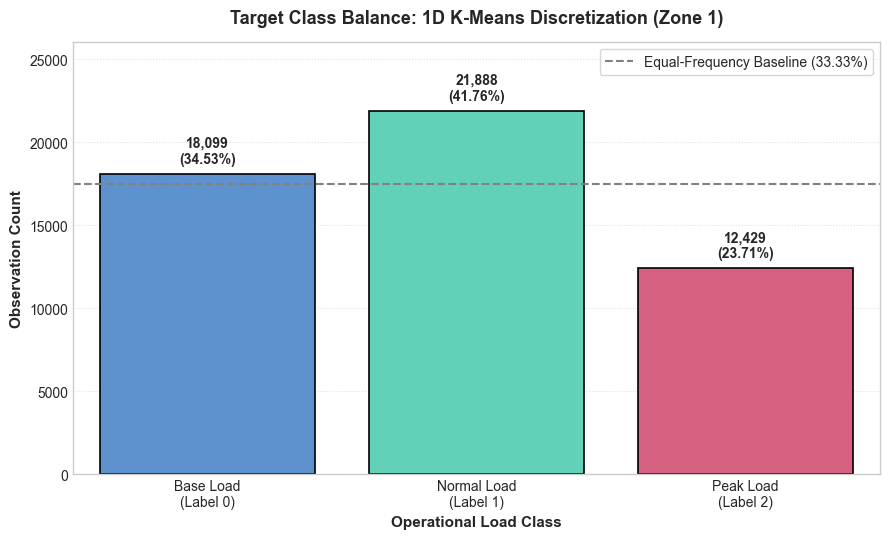

Baseline dataset saved to: 'data/converted_power_consumption.csv' | Shape: (52416, 8)
Baseline dataset saved to: '../data/converted_power_consumption.csv' | Shape: (52416, 8)

=== Baseline Dataset Preview (First 5 Rows) ===


,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,hour,month,zone_1_load_class
0,6.559,73.8,0.083,0.051,0.119,0,1,1
1,6.414,74.5,0.083,0.070,0.085,0,1,1
2,6.313,74.5,0.080,0.062,0.100,0,1,1
3,6.121,75.0,0.083,0.091,0.096,0,1,0
4,5.921,75.7,0.081,0.048,0.085,0,1,0


In [22]:
# ==========================================
# Task 1: Target Variable Preparation (1D K-Means)
# ==========================================
target_col = 'zone_1_power_consumption'
target_values = df[target_col].values.reshape(-1, 1)

# 1. Fit 1D K-Means Clustering (3 clusters, fixed random_state for reproducibility)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(target_values)

# 2. Extract and sort cluster centroids in ascending order
raw_centroids = kmeans.cluster_centers_.flatten()
sorted_indices = np.argsort(raw_centroids)
sorted_centroids = raw_centroids[sorted_indices]

# 3. Create mapping to ensure label 0 = lowest centroid, 2 = highest centroid
label_mapping = {old_label: new_rank for new_rank, old_label in enumerate(sorted_indices)}
class_names = {0: 'Base Load', 1: 'Normal Load', 2: 'Peak Load'}

# Assign sorted ordinal target labels (0, 1, 2)
df['zone_1_load_class'] = pd.Series(kmeans.labels_).map(label_mapping)
df['zone_1_load_name'] = df['zone_1_load_class'].map(class_names)

# 4. Calculate exact kW boundary thresholds (midpoints between adjacent centroids)
boundary_0_1 = (sorted_centroids[0] + sorted_centroids[1]) / 2.0
boundary_1_2 = (sorted_centroids[1] + sorted_centroids[2]) / 2.0

print("=" * 70)
print("=== 1D K-MEANS CLUSTER CENTROIDS & BOUNDARIES ===")
print("=" * 70)
print(f"Centroid 0 (Base Load)   : {sorted_centroids[0]:,.2f} kW")
print(f"Centroid 1 (Normal Load) : {sorted_centroids[1]:,.2f} kW")
print(f"Centroid 2 (Peak Load)   : {sorted_centroids[2]:,.2f} kW")
print(f"\nDecision Boundary [Base -> Normal] (0 -> 1) : {boundary_0_1:,.2f} kW")
print(f"Decision Boundary [Normal -> Peak] (1 -> 2) : {boundary_1_2:,.2f} kW")

# 5. Comparative Evaluation against Portfolio 1 qcut Thresholds
qcut_t1 = 28563.46
qcut_t2 = 35440.43

comparison_df = pd.DataFrame([
    {
        'Operational Transition': 'Base Load -> Normal Load',
        'Portfolio 1 (pd.qcut)': f"{qcut_t1:,.2f} kW",
        'Portfolio 2 (1D K-Means)': f"{boundary_0_1:,.2f} kW",
        'Absolute Shift (kW)': f"{boundary_0_1 - qcut_t1:+,.2f} kW",
        'Percentage Shift (%)': f"{((boundary_0_1 - qcut_t1) / qcut_t1) * 100:+.2f}%"
    },
    {
        'Operational Transition': 'Normal Load -> Peak Load',
        'Portfolio 1 (pd.qcut)': f"{qcut_t2:,.2f} kW",
        'Portfolio 2 (1D K-Means)': f"{boundary_1_2:,.2f} kW",
        'Absolute Shift (kW)': f"{boundary_1_2 - qcut_t2:+,.2f} kW",
        'Percentage Shift (%)': f"{((boundary_1_2 - qcut_t2) / qcut_t2) * 100:+.2f}%"
    }
])

print("\n=== COMPARISON TABLE: DISCRETIZATION THRESHOLDS ===")
display(comparison_df)

# 6. Class Distribution & Balance Verification
counts = df['zone_1_load_class'].value_counts().sort_index()
proportions = (df['zone_1_load_class'].value_counts(normalize=True) * 100).sort_index()

dist_df = pd.DataFrame({
    'Ordinal Label': counts.index,
    'Class Name': [class_names[i] for i in counts.index],
    'Centroid (kW)': [f"{sorted_centroids[i]:,.2f}" for i in counts.index],
    'Sample Count': [f"{c:,}" for c in counts.values],
    'Proportion (%)': [f"{p:.2f}%" for p in proportions.values]
})

print("\n=== TARGET CLASS DISTRIBUTION TABLE ===")
display(dist_df)

# Class balance assertion: confirm no single class exceeds 80%
max_prop = proportions.max()
assert max_prop <= 80.0, f"Class balance violation: maximum class proportion ({max_prop:.2f}%) exceeds 80%!"
print(f"[VERIFIED] No class exceeds 80% threshold (Maximum class proportion = {max_prop:.2f}%).")

# 7. Visualization: Bar Chart of Class Balance
plt.figure(figsize=(9, 5.5))
palette = ['#4A90E2', '#50E3C2', '#E94E77']
ax = sns.barplot(
    x=[f"{class_names[i]}\n(Label {i})" for i in counts.index],
    y=counts.values,
    palette=palette,
    hue=[f"{class_names[i]}\n(Label {i})" for i in counts.index],
    legend=False,
    edgecolor='black',
    linewidth=1.2
)

plt.title('Target Class Balance: 1D K-Means Discretization (Zone 1)', fontsize=13, fontweight='bold', pad=14)
plt.xlabel('Operational Load Class', fontsize=11, fontweight='bold')
plt.ylabel('Observation Count', fontsize=11, fontweight='bold')
plt.ylim(0, 26000)
plt.axhline(len(df) / 3, color='gray', linestyle='--', linewidth=1.5, label='Equal-Frequency Baseline (33.33%)')
plt.legend(loc='upper right', frameon=True)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Annotate exact counts and percentages above bars
for p, prop in zip(ax.patches, proportions.values):
    count_val = int(p.get_height())
    ax.annotate(
        f"{count_val:,}\n({prop:.2f}%)",
        (p.get_x() + p.get_width() / 2., p.get_height() + 450),
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

plt.tight_layout()
plt.show()

# ==========================================
# 8. Baseline Dataset Export & Target Leakage Prevention
# ==========================================
# Strict isolation: 7 original predictors + encoded target zone_1_load_class
baseline_cols = predictor_cols + ['zone_1_load_class']
baseline_df = df[baseline_cols].copy()

# Leakage checks & programmatic assertions
assert target_col not in baseline_df.columns, "CRITICAL ERROR: Continuous target found in baseline dataset!"
assert 'datetime' not in baseline_df.columns, "CRITICAL ERROR: Datetime column found in baseline dataset!"
assert 'zone_2_power_consumption' not in baseline_df.columns, "CRITICAL ERROR: Zone 2 telemetry found in baseline dataset!"
assert 'zone_3_power_consumption' not in baseline_df.columns, "CRITICAL ERROR: Zone 3 telemetry found in baseline dataset!"
assert baseline_df.shape == (52416, 8), f"Unexpected baseline dataset shape: {baseline_df.shape}"
assert baseline_df.isnull().sum().sum() == 0, "CRITICAL ERROR: Missing values detected in baseline dataset!"

# Export baseline CSV (analogous to converted_concrete.csv in Studio 3 Activity 1)
output_paths = ['data/converted_power_consumption.csv']
if os.path.exists('../data'):
    output_paths.append('../data/converted_power_consumption.csv')

for out_path in output_paths:
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    baseline_df.to_csv(out_path, index=False)
    print(f"Baseline dataset saved to: '{out_path}' | Shape: {baseline_df.shape}")

print("\n=== Baseline Dataset Preview (First 5 Rows) ===")
display(baseline_df.head())


---

## Task 2: Feature Normalization, Transformation & Encoding Strategy

### Technical Overview & Distributional Rationale:
In **Portfolio 1 Task 4**, rigorous exploratory data analysis uncovered that the 7 numerical predictors exhibit wildly divergent distributional morphology: from near-Gaussian thermal patterns, to bimodal wind regimes, to uniform time cycles, and extreme zero-inflated leptokurtic solar fluxes. Applying a naive, uniform scaling strategy (e.g., standardizing everything with `StandardScaler` or clamping with `MinMaxScaler`) corrupts statistical variance, inflates outlier leverage, or distorts physical boundaries.

To optimize gradient convergence and distance computations across multi-class algorithms while preserving domain realism, we implement **feature-specific transformations** tailored to each feature's empirical profile:

#### 1. Task 2.1: Feature-Specific Scaling Prescription
- **StandardScaler** ($z = \frac{x - \mu}{\sigma}$):
  - `temperature` ($\text{skew} = +0.20$, $\text{kurtosis} = -0.30$, $0.00\%$ outliers): Demonstrates near-Gaussian symmetry across diurnal and seasonal cycles. Standardization centers the mean at 0 with unit variance.
  - `humidity` ($\text{skew} = -0.63$, $\text{kurtosis} = -0.12$, $0.00\%$ outliers): Exhibits moderate negative skewness without extreme tail contamination. StandardScaler preserves psychrometric spread without distorting natural boundaries.
- **MinMaxScaler** ($x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$):
  - `wind_speed` ($\text{skew} = +0.46$, $\text{kurtosis} = -1.78$, $0.00\%$ outliers): Distinctly bimodal distribution (calm microclimate vs. active coastal wind events) with zero IQR outliers. Bounding strictly to $[0, 1]$ preserves the separation between the dual operational modes.
  - `hour` (uniform cyclical, $0\text{--}23$): Exactly uniform discrete distribution ($2,184$ samples per integer bin, $0.00\%$ outliers). Clamping to $[0, 1]$ normalizes diurnal progression into a unit continuum.
  - `month` (uniform discrete, $1\text{--}12$): Uniform calendar sequence ($0.00\%$ outliers). Normalizes seasonal intervals onto $[0, 1]$.
- **RobustScaler** ($z = \frac{x - Q_2}{\text{IQR}}$):
  - `general_diffuse_flows` ($\text{skew} = +1.31$, $\text{kurtosis} = +0.40$, $4.42\%$ outliers): Zero-inflated night profile paired with a long, thin daytime solar tail. Robust scaling centers on the median ($5.04\text{ W/m}^2$) and scales by the interquartile range (IQR), immunizing against outlier shrinkage.
  - `diffuse_flows` ($\text{skew} = +2.46$, $\text{kurtosis} = +7.00$, $8.72\%$ outliers): Severely right-skewed and leptokurtic with 4,572 genuine physical solar peaks. Centering via median and scaling via IQR prevents solar flare leverage from dominating loss gradients.

#### 2. Task 2.2: Categorical & Ordinal Encoding Strategy
- **Target Variable (`zone_1_load_class`)**: Preserved as an **ordinal integer encoding** (`0: Base Load`, `1: Normal Load`, `2: Peak Load`). This aligns with Scikit-Learn tree and linear classifier specifications while encoding the monotonic thermodynamic relationship ($c_0 < c_1 < c_2$).
- **Engineered Regime Indicators Policy**:
  - Binary regime flags (e.g., `is_daylight`, `is_weekend`): Handled via **Binary Label Encoding** ($0$ or $1$).
  - Low-cardinality nominal features ($<10$ categories, e.g., `season`): Handled via **One-Hot Encoding** (`drop_first=True` or dummy expansion) to prevent artificial ordinal assumptions.

#### 3. Task 2.3: Documentation & Dataset Export
- Output a comprehensive architectural specification table mapping every feature to its skewness, outlier proportion, exact scaling transformation, and engineering justification.
- Export the processed 7-feature dataset to `normalised_power_consumption.csv` (strictly analogous to `normalised_concrete.csv` in Studio 3).


Loaded baseline dataset from: 'data/converted_power_consumption.csv' | Shape: (52416, 8)
=== FEATURE SCALING & ENCODING VERIFIED SUCCESSFULLY ===
Dataset Dimensions : 52,416 rows x 8 columns
Target Feature     : 'zone_1_load_class' with ordinal values [0, 1, 2]

=== TASK 2.3: FEATURE TRANSFORMATION SPECIFICATION TABLE (RECOMPUTED) ===


,Feature Name,Role,Recomputed EDA Profile,Applied Scaler / Encoder,Engineering Justification
0,temperature,Predictor,"Skew = +0.20, Kurt = -0.30, Outliers = 0.27% (142)",StandardScaler,Near-Gaussian thermal symmetry across diurnal/seasonal cycles; centers mean to 0 and variance to 1.
1,humidity,Predictor,"Skew = -0.63, Kurt = -0.12, Outliers = 0.56% (291)",StandardScaler,Moderate negative skew without extreme tail anomalies; preserves relative moisture dynamics.
2,wind_speed,Predictor,"Skew = +0.46, Kurt = -1.78, Outliers = 0.00% (0)",MinMaxScaler,"Bimodal operational regime (calm vs active wind) with zero statistical outliers; bounded [0, 1] preserves mode separation."
3,hour,Predictor,"Skew = +0.00, Kurt = -1.20, Outliers = 0.00% (0)",MinMaxScaler,Uniform integer cycle (0 to 23); linearly maps diurnal intervals onto a continuous bounded unit interval.
4,month,Predictor,"Skew = -0.01, Kurt = -1.20, Outliers = 0.00% (0)",MinMaxScaler,Uniform discrete calendar sequence (1 to 12); normalizes annual seasonality onto a standardized unit scale.
5,general_diffuse_flows,Predictor,"Skew = +1.31, Kurt = +0.40, Outliers = 4.42% (2,315)",RobustScaler,Zero-inflated night baseline and heavy daytime solar tail; centers at median and scales via IQR to resist outlier compression.
6,diffuse_flows,Predictor,"Skew = +2.46, Kurt = +7.00, Outliers = 8.72% (4,571)",RobustScaler,Severely leptokurtic right tail with physical solar outliers; median/IQR scaling prevents gradient inflation and scale collapse.
7,zone_1_load_class,Target Variable,"K-Means: Base (34.5%), Normal (41.8%), Peak (23.7%)",Ordinal Integer Encoding,Preserves strict monotonic ordinal wattage hierarchy (c0 < c1 < c2) while maintaining native compatibility with multi-class learners.


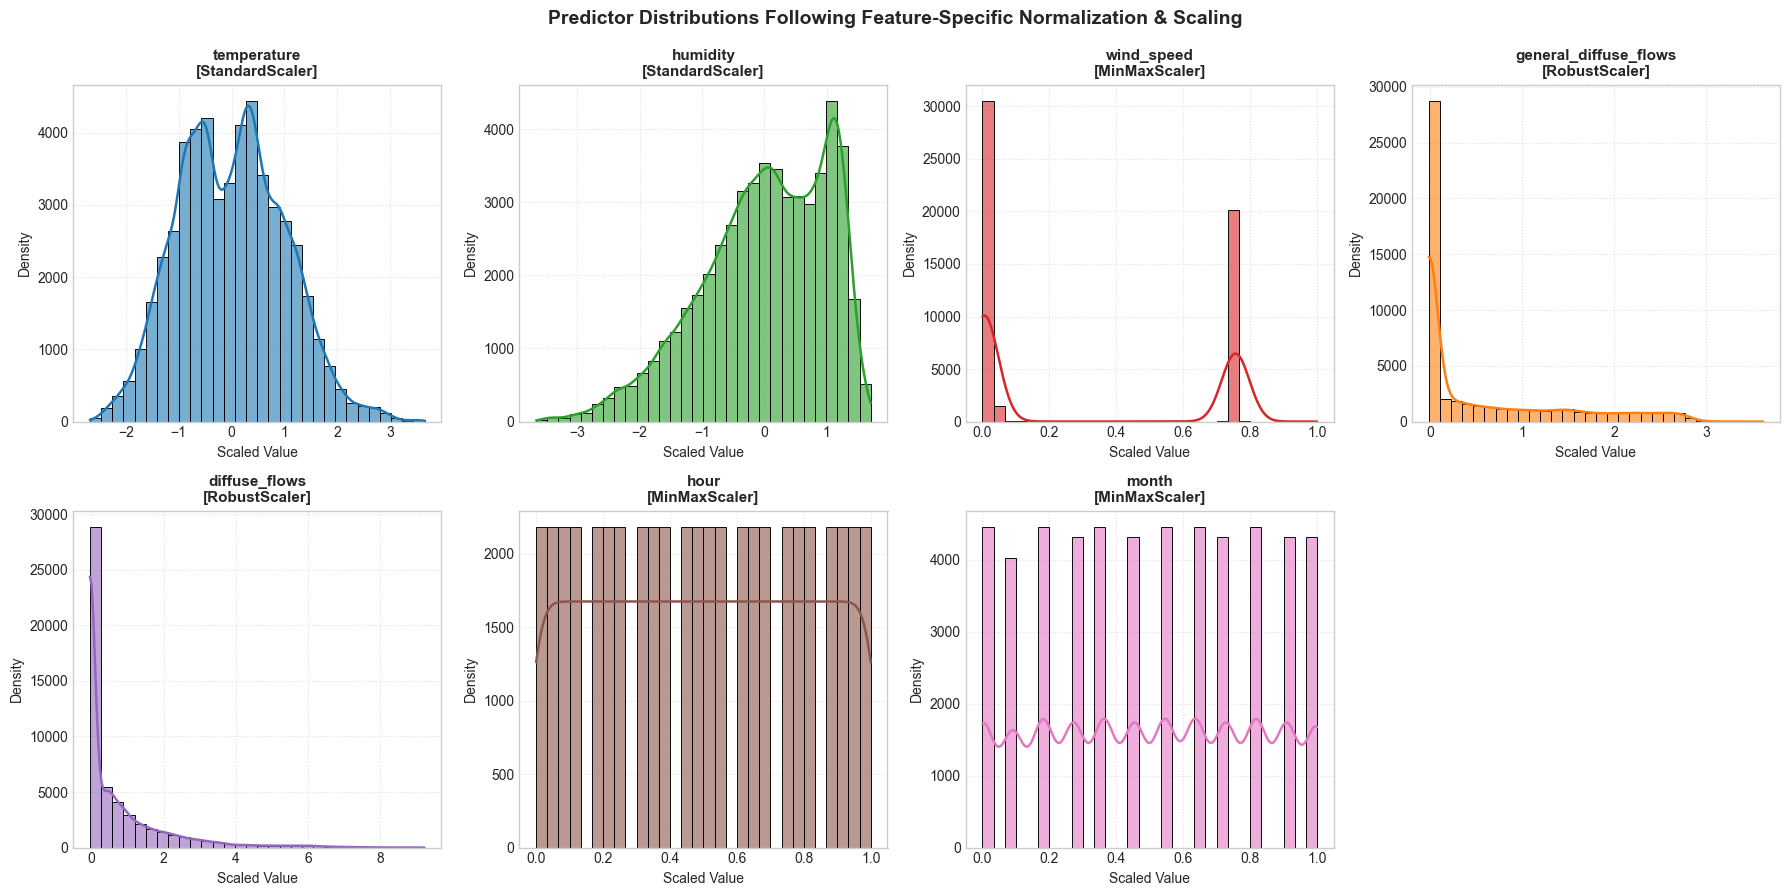


=== Scaled Predictors Summary Statistics (df_norm.describe()) ===


,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,hour,month,zone_1_load_class
count,52416.0000,52416.0000,52416.0000,52416.0000,52416.0000,52416.000,52416.0000,52416.0000
mean,0.0000,0.0000,0.2968,0.5560,0.6996,0.500,0.5010,0.8918
std,1.0000,1.0000,0.3651,0.8274,1.2313,0.301,0.3128,0.7555
min,-2.6762,-3.6602,0.0000,-0.0157,-0.0441,0.000,0.0000,0.0000
25%,-0.7566,-0.6398,0.0044,-0.0156,-0.0430,0.250,0.2727,0.0000
50%,-0.0052,0.1029,0.0056,0.0000,0.0000,0.500,0.5455,1.0000
75%,0.7016,0.8450,0.7563,0.9844,0.9570,0.750,0.7500,1.0000
max,3.6455,1.7067,1.0000,3.6239,9.2344,1.000,1.0000,2.0000


Normalized baseline dataset exported to: 'data/normalised_power_consumption.csv' | Shape: (52416, 8)
Normalized baseline dataset exported to: '../data/normalised_power_consumption.csv' | Shape: (52416, 8)

=== Normalized Dataset Preview (First 5 Rows) ===


,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,hour,month,zone_1_load_class
0,-2.106645,0.356277,0.005130,-0.015599,-0.042993,0.0,0.0,1
1,-2.131578,0.401291,0.005130,-0.015540,-0.043330,0.0,0.0,1
2,-2.148946,0.401291,0.004663,-0.015565,-0.043181,0.0,0.0,1
3,-2.181962,0.433443,0.005130,-0.015474,-0.043221,0.0,0.0,0
4,-2.216353,0.478456,0.004819,-0.015608,-0.043330,0.0,0.0,0


In [23]:
# ==========================================
# Task 2: Feature Normalization & Transformation
# ==========================================
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# 1. Load Baseline Dataset (Unscaled 7 Predictors + Encoded Target)
baseline_path = 'data/converted_power_consumption.csv'
if not os.path.exists(baseline_path):
    baseline_path = 'portfolio/data/converted_power_consumption.csv'

df_base = pd.read_csv(baseline_path)
print(f"Loaded baseline dataset from: '{baseline_path}' | Shape: {df_base.shape}")

# 2. Partition Features into Defined Scaling Prescriptions (Task 2.1)
standard_features = ['temperature', 'humidity']
minmax_features = ['wind_speed', 'hour', 'month']
robust_features = ['general_diffuse_flows', 'diffuse_flows']
target_feature = 'zone_1_load_class'

# Instantiate domain-specific scalers
scaler_standard = StandardScaler()
scaler_minmax = MinMaxScaler()
scaler_robust = RobustScaler()

# Apply transformations independently
df_norm = pd.DataFrame(index=df_base.index)

# A. StandardScaler: Near-Gaussian / moderate skew features
df_norm[standard_features] = scaler_standard.fit_transform(df_base[standard_features])

# B. MinMaxScaler: Bimodal & bounded uniform discrete features
df_norm[minmax_features] = scaler_minmax.fit_transform(df_base[minmax_features])

# C. RobustScaler: Zero-inflated, highly skewed solar telemetry with heavy outliers
df_norm[robust_features] = scaler_robust.fit_transform(df_base[robust_features])

# Maintain consistent predictor ordering
ordered_features = [
    'temperature',
    'humidity',
    'wind_speed',
    'general_diffuse_flows',
    'diffuse_flows',
    'hour',
    'month'
]
df_norm = df_norm[ordered_features]

# Task 2.2: Attach ordinal-encoded target (0: Base, 1: Normal, 2: Peak)
df_norm[target_feature] = df_base[target_feature].astype(int)

# ==========================================
# 3. Quality Assurance & Mathematical Sanity Assertions
# ==========================================
# Verify shape and column completeness
assert df_norm.shape == (52416, 8), f"Dimension mismatch: expected (52416, 8), got {df_norm.shape}"
assert list(df_norm.columns) == ordered_features + [target_feature], "Column schema misalignment!"

# Verify StandardScaler properties: mean ~ 0, std ~ 1
for col in standard_features:
    assert abs(df_norm[col].mean()) < 1e-4, f"StandardScaler mean deviation on {col}"
    assert abs(df_norm[col].std() - 1.0) < 1e-4, f"StandardScaler variance deviation on {col}"

# Verify MinMaxScaler properties: min = 0, max = 1
for col in minmax_features:
    assert abs(df_norm[col].min() - 0.0) < 1e-6, f"MinMaxScaler min out of bounds on {col}"
    assert abs(df_norm[col].max() - 1.0) < 1e-6, f"MinMaxScaler max out of bounds on {col}"

# Verify RobustScaler properties: median = 0
for col in robust_features:
    assert abs(df_norm[col].median() - 0.0) < 1e-6, f"RobustScaler median deviation on {col}"

# Verify Target Encoding integrity
assert set(df_norm[target_feature].unique()) == {0, 1, 2}, "Target classes must strictly be {0, 1, 2}!"
assert df_norm.isnull().sum().sum() == 0, "Missing values detected post-scaling!"

print("=" * 70)
print("=== FEATURE SCALING & ENCODING VERIFIED SUCCESSFULLY ===")
print("=" * 70)
print(f"Dataset Dimensions : {df_norm.shape[0]:,} rows x {df_norm.shape[1]} columns")
print(f"Target Feature     : '{target_feature}' with ordinal values {sorted(df_norm[target_feature].unique().tolist())}")

# ==========================================
# 4. Task 2.3: Summary Documentation Table (Dynamically Recomputed EDA Profiles)
# ==========================================
# Dynamically recompute skewness, kurtosis, and IQR outlier percentages directly on baseline data
dynamic_profiles = {}
for col in ordered_features:
    s = df_base[col].skew()
    k = df_base[col].kurtosis()
    q1 = df_base[col].quantile(0.25)
    q3 = df_base[col].quantile(0.75)
    iqr = q3 - q1
    out_cnt = ((df_base[col] < (q1 - 1.5 * iqr)) | (df_base[col] > (q3 + 1.5 * iqr))).sum()
    out_pct = (out_cnt / len(df_base)) * 100
    dynamic_profiles[col] = f"Skew = {s:+.2f}, Kurt = {k:+.2f}, Outliers = {out_pct:.2f}% ({out_cnt:,})"

target_counts = df_base[target_feature].value_counts().sort_index()
target_pcts = (df_base[target_feature].value_counts(normalize=True) * 100).sort_index()
target_profile = f"K-Means: Base ({target_pcts[0]:.1f}%), Normal ({target_pcts[1]:.1f}%), Peak ({target_pcts[2]:.1f}%)"

spec_table = pd.DataFrame([
    {
        'Feature Name': 'temperature',
        'Role': 'Predictor',
        'Recomputed EDA Profile': dynamic_profiles['temperature'],
        'Applied Scaler / Encoder': 'StandardScaler',
        'Engineering Justification': 'Near-Gaussian thermal symmetry across diurnal/seasonal cycles; centers mean to 0 and variance to 1.'
    },
    {
        'Feature Name': 'humidity',
        'Role': 'Predictor',
        'Recomputed EDA Profile': dynamic_profiles['humidity'],
        'Applied Scaler / Encoder': 'StandardScaler',
        'Engineering Justification': 'Moderate negative skew without extreme tail anomalies; preserves relative moisture dynamics.'
    },
    {
        'Feature Name': 'wind_speed',
        'Role': 'Predictor',
        'Recomputed EDA Profile': dynamic_profiles['wind_speed'],
        'Applied Scaler / Encoder': 'MinMaxScaler',
        'Engineering Justification': 'Bimodal operational regime (calm vs active wind) with zero statistical outliers; bounded [0, 1] preserves mode separation.'
    },
    {
        'Feature Name': 'hour',
        'Role': 'Predictor',
        'Recomputed EDA Profile': dynamic_profiles['hour'],
        'Applied Scaler / Encoder': 'MinMaxScaler',
        'Engineering Justification': 'Uniform integer cycle (0 to 23); linearly maps diurnal intervals onto a continuous bounded unit interval.'
    },
    {
        'Feature Name': 'month',
        'Role': 'Predictor',
        'Recomputed EDA Profile': dynamic_profiles['month'],
        'Applied Scaler / Encoder': 'MinMaxScaler',
        'Engineering Justification': 'Uniform discrete calendar sequence (1 to 12); normalizes annual seasonality onto a standardized unit scale.'
    },
    {
        'Feature Name': 'general_diffuse_flows',
        'Role': 'Predictor',
        'Recomputed EDA Profile': dynamic_profiles['general_diffuse_flows'],
        'Applied Scaler / Encoder': 'RobustScaler',
        'Engineering Justification': 'Zero-inflated night baseline and heavy daytime solar tail; centers at median and scales via IQR to resist outlier compression.'
    },
    {
        'Feature Name': 'diffuse_flows',
        'Role': 'Predictor',
        'Recomputed EDA Profile': dynamic_profiles['diffuse_flows'],
        'Applied Scaler / Encoder': 'RobustScaler',
        'Engineering Justification': 'Severely leptokurtic right tail with physical solar outliers; median/IQR scaling prevents gradient inflation and scale collapse.'
    },
    {
        'Feature Name': 'zone_1_load_class',
        'Role': 'Target Variable',
        'Recomputed EDA Profile': target_profile,
        'Applied Scaler / Encoder': 'Ordinal Integer Encoding',
        'Engineering Justification': 'Preserves strict monotonic ordinal wattage hierarchy (c0 < c1 < c2) while maintaining native compatibility with multi-class learners.'
    }
])
styled_table = spec_table.style.set_properties(
    **{
        "text-align": "left",
        "white-space": "pre-wrap", 
        "word-break": "break-word", 
    }
)

print("\n=== TASK 2.3: FEATURE TRANSFORMATION SPECIFICATION TABLE (RECOMPUTED) ===")
display(styled_table)

# ==========================================
# 5. Visualization: Scaled Predictor Distribution Comparison
# ==========================================
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 9))
axes = axes.ravel()
palette_colors = ['#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#8c564b', '#e377c2']

for i, col in enumerate(ordered_features):
    sns.histplot(
        df_norm[col],
        kde=True,
        ax=axes[i],
        color=palette_colors[i],
        bins=30,
        edgecolor='black',
        alpha=0.6,
        line_kws={'linewidth': 1.8}
    )
    scaler_type = spec_table.loc[spec_table['Feature Name'] == col, 'Applied Scaler / Encoder'].values[0]
    axes[i].set_title(f"{col}\n[{scaler_type}]", fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Scaled Value', fontsize=10)
    axes[i].set_ylabel('Density', fontsize=10)
    axes[i].grid(True, linestyle=':', alpha=0.6)

# Hide unused 8th subplot
fig.delaxes(axes[7])
plt.suptitle('Predictor Distributions Following Feature-Specific Normalization & Scaling', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

# ==========================================
# 6. Summary Statistics & Baseline CSV Export
# ==========================================
print("\n=== Scaled Predictors Summary Statistics (df_norm.describe()) ===")
display(df_norm.describe().round(4))

# Export normalized dataset (analogous to normalised_concrete.csv in Studio 3)
norm_export_paths = ['data/normalised_power_consumption.csv']
if os.path.exists('../data'):
    norm_export_paths.append('../data/normalised_power_consumption.csv')

for out_path in norm_export_paths:
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    df_norm.to_csv(out_path, index=False)
    print(f"Normalized baseline dataset exported to: '{out_path}' | Shape: {df_norm.shape}")

print("\n=== Normalized Dataset Preview (First 5 Rows) ===")
display(df_norm.head())


---

## Task 3: Domain-Specific Feature Engineering & Multicollinearity Diagnostics

### Technical Overview & Domain Motivation:
While the 7 baseline predictors capture raw sensory inputs, physical thermodynamic processes in an electrical distribution grid involve non-linear couplings, atmospheric heat gains, and strict human diurnal routines. Motivated by our findings in **Portfolio 1 EDA**, we construct 9 domain-specific engineered features:

1. **Solar Clearness & Collinearity Resolution**:
   - `diffuse_fraction` = $\frac{\text{diffuse\_flows}}{\text{general\_diffuse\_flows} + 10^{-5}}$
   - *Motivation*: In Portfolio 1 Task 5, `general_diffuse_flows` and `diffuse_flows` exhibited strong domain redundancy ($r = +0.5647$). This ratio isolates atmospheric clearness and cloud scattering from raw solar magnitude. A small epsilon ($10^{-5}$) prevents division-by-zero during nighttime zero-inflated intervals.
2. **Thermal-Moisture Enthalpy**:
   - `temp_humidity_index` = $\text{temperature} \times \text{humidity}$
   - *Motivation*: Models latent heat and humid air enthalpy. Air conditioning cooling loads spike non-linearly when high temperature coincides with elevated humidity.
3. **Radiative Heat Gain**:
   - `solar_thermal_load` = $\text{general\_diffuse\_flows} \times \text{temperature}$
   - *Motivation*: Captures building solar radiation absorption, which amplifies indoor cooling demands beyond ambient temperature alone.
4. **Microclimate Ventilation**:
   - `convective_cooling_ratio` = $\frac{\text{temperature}}{\text{wind\_speed} + 1.0}$
   - *Motivation*: Captures the thermal relief provided by coastal Mediterranean sea breezes versus stagnant heat accumulation.
5. **Periodic Harmonic Cycles (Diurnal & Annual)**:
   - `hour_sin` = $\sin\left(\frac{2\pi \cdot \text{hour}}{24}\right)$, `hour_cos` = $\cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$
   - `month_sin` = $\sin\left(\frac{2\pi \cdot (\text{month}-1)}{12}\right)$, `month_cos` = $\cos\left(\frac{2\pi \cdot (\text{month}-1)}{12}\right)$
   - *Motivation*: Eliminates the artificial boundary jump between 23:00 ($1.0$) and 00:00 ($0.0$), and uncovers the non-linear U-shaped annual seasonality where raw calendar month showed a deceptive $r = -0.0053$ in Portfolio 1.
6. **Evening Operational Regime Flag**:
   - `is_evening_peak` = $1$ if $\text{hour} \in [17, 22]$ else $0$
   - *Motivation*: Formally encodes the municipal evening residential surge identified in Portfolio 1 pairplots into an explicit binary indicator (satisfying Task 2.2 Binary Label Encoding $0/1$).

#### Scaling & Multicollinearity Analysis Strategy:
- Continuous engineered features are normalized using tailored scalers (`RobustScaler` for solar ratios/loads; `StandardScaler` for thermal interactions).
- Multicollinearity is comprehensively diagnosed via **Pearson Correlation Heatmap** and **Variance Inflation Factor (VIF)** analysis across both raw and interaction terms.
- The complete 16-predictor normalized feature set is exported to `features_power_consumption.csv`.


=== FULL FEATURE MATRIX ASSEMBLED (16 Predictors + 1 Target) ===
Shape: 52,416 rows x 17 columns

=== TOP CORRELATIONS WITH TARGET (zone_1_load_class) ===


,Feature,Pearson r,Absolute |r|,Direction,Feature Category
Rank,,,,,
1,hour_sin,-0.730365,0.730365,Negative,Engineered
2,hour,0.711362,0.711362,Positive,Original
3,is_evening_peak,0.609718,0.609718,Positive,Engineered
4,temperature,0.392136,0.392136,Positive,Original
5,humidity,-0.288788,0.288788,Negative,Original
6,month_cos,-0.225282,0.225282,Negative,Engineered
7,solar_thermal_load,0.224492,0.224492,Positive,Engineered
8,diffuse_fraction,-0.208195,0.208195,Negative,Engineered
9,general_diffuse_flows,0.191606,0.191606,Positive,Original



=== VIF ANALYSIS: ORIGINAL 7 PREDICTORS (BASELINE) ===


,Feature,R-Squared (vs Others),VIF,Collinearity Severity
0,temperature,0.5047,2.02,Low (VIF < 5)
1,general_diffuse_flows,0.4902,1.96,Low (VIF < 5)
2,diffuse_flows,0.3400,1.52,Low (VIF < 5)
3,humidity,0.3215,1.47,Low (VIF < 5)
4,wind_speed,0.2494,1.33,Low (VIF < 5)
5,month,0.1295,1.15,Low (VIF < 5)
6,hour,0.0821,1.09,Low (VIF < 5)



=== VIF ANALYSIS: FULL PREDICTOR SPACE (ORIGINAL + ENGINEERED) ===


,Feature,R-Squared (vs Others),VIF,Collinearity Severity
0,general_diffuse_flows,0.9734,37.65,Severe (VIF >= 10)
1,solar_thermal_load,0.9724,36.28,Severe (VIF >= 10)
2,temperature,0.9666,29.98,Severe (VIF >= 10)
3,temp_humidity_index,0.9484,19.38,Severe (VIF >= 10)
4,wind_speed,0.9423,17.34,Severe (VIF >= 10)
5,humidity,0.9354,15.48,Severe (VIF >= 10)
6,convective_cooling_ratio,0.9265,13.61,Severe (VIF >= 10)
7,month_cos,0.8262,5.75,Moderate (5 <= VIF < 10)
8,hour_sin,0.7448,3.92,Low (VIF < 5)
9,hour_cos,0.7238,3.62,Low (VIF < 5)


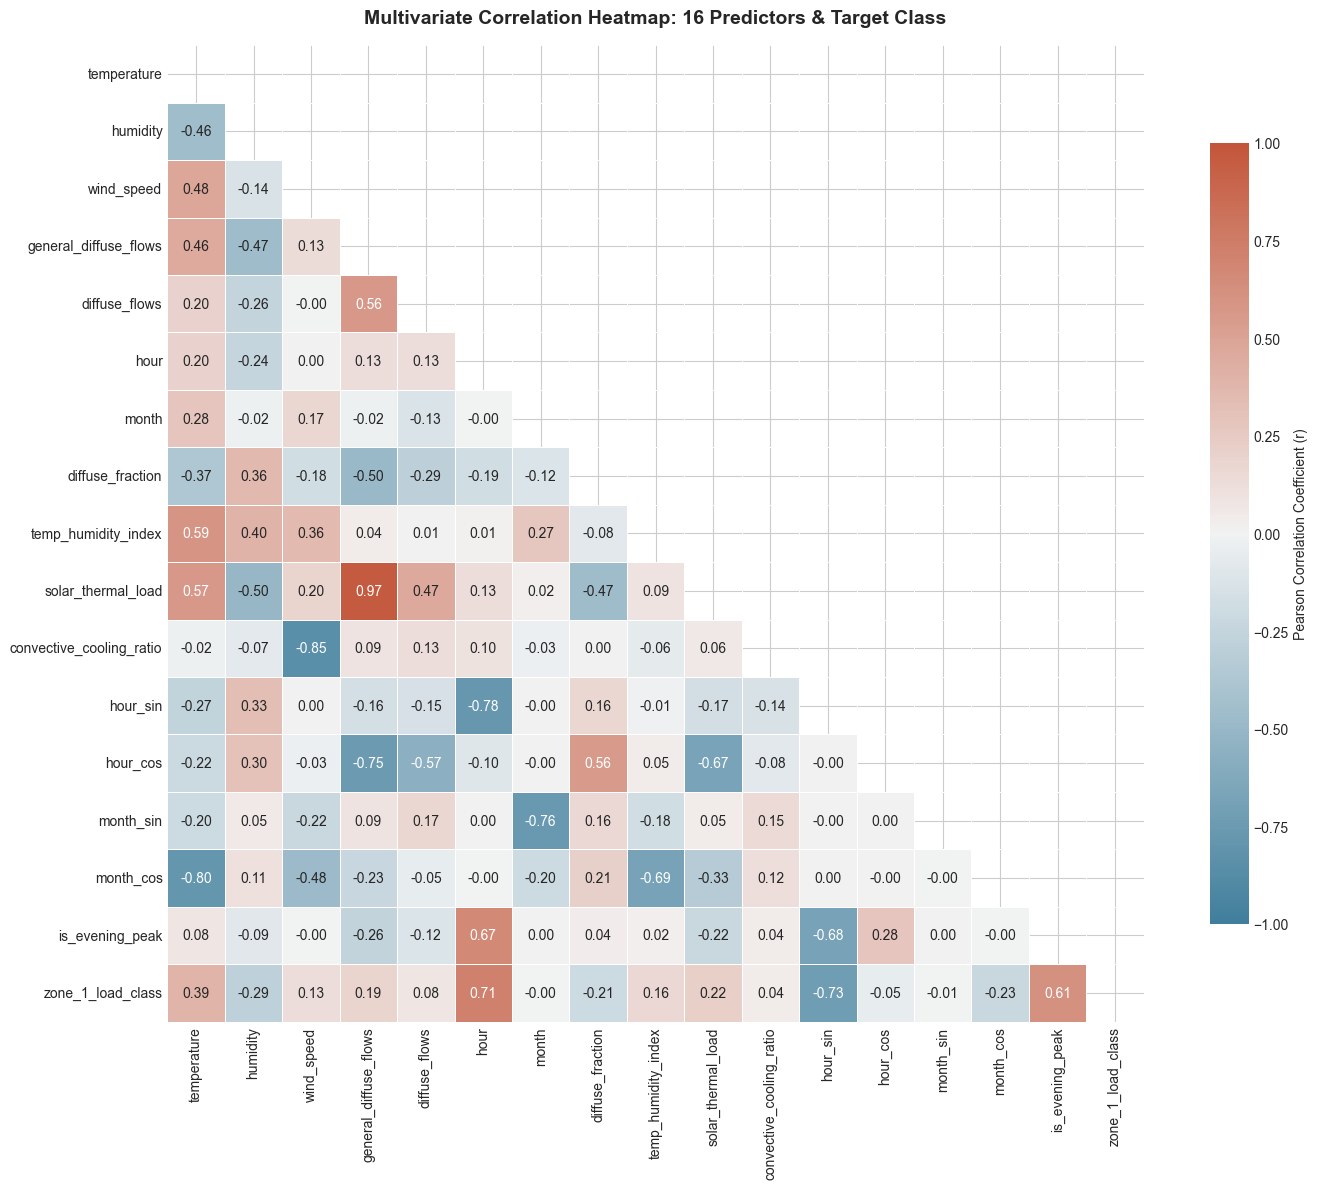

Full engineered dataset successfully saved to: 'data/features_power_consumption.csv' | Shape: (52416, 17)
Full engineered dataset successfully saved to: '../data/features_power_consumption.csv' | Shape: (52416, 17)

=== Full Engineered Dataset Preview (First 5 Rows) ===


,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,hour,month,diffuse_fraction,temp_humidity_index,solar_thermal_load,convective_cooling_ratio,hour_sin,hour_cos,month_sin,month_cos,is_evening_peak,zone_1_load_class
0,-2.106645,0.356277,0.005130,-0.015599,-0.042993,0.0,0.0,1.162589,-1.955601,-0.013370,-0.719941,0.0,1.0,0.0,1.0,0,1
1,-2.131578,0.401291,0.005130,-0.015540,-0.043330,0.0,0.0,0.181837,-1.971620,-0.013351,-0.740378,0.0,1.0,0.0,1.0,0,1
2,-2.148946,0.401291,0.004663,-0.015565,-0.043181,0.0,0.0,0.531204,-1.991025,-0.013360,-0.752142,0.0,1.0,0.0,1.0,0,1
3,-2.181962,0.433443,0.005130,-0.015474,-0.043221,0.0,0.0,0.042203,-2.020022,-0.013333,-0.781674,0.0,1.0,0.0,1.0,0,0
4,-2.216353,0.478456,0.004819,-0.015608,-0.043330,0.0,0.0,0.669557,-2.048018,-0.013378,-0.808319,0.0,1.0,0.0,1.0,0,0


In [24]:
# ==========================================
# Task 3: Domain-Specific Feature Engineering
# ==========================================
from sklearn.linear_model import LinearRegression

# 1. Load unscaled baseline features
baseline_path = 'data/converted_power_consumption.csv'
if not os.path.exists(baseline_path):
    baseline_path = 'portfolio/data/converted_power_consumption.csv'

df_raw = pd.read_csv(baseline_path)

# 2. Engineer Domain-Specific Features
# A. Solar Clearness Ratio (resolves r = +0.5647 solar sensor redundancy)
df_raw['diffuse_fraction'] = df_raw['diffuse_flows'] / (df_raw['general_diffuse_flows'] + 1e-5)

# B. Thermodynamic & Psychrometric Interactions
df_raw['temp_humidity_index'] = df_raw['temperature'] * df_raw['humidity']
df_raw['solar_thermal_load'] = df_raw['general_diffuse_flows'] * df_raw['temperature']
df_raw['convective_cooling_ratio'] = df_raw['temperature'] / (df_raw['wind_speed'] + 1.0)

# C. Cyclical Harmonic Transformations (Diurnal & Seasonal)
df_raw['hour_sin'] = np.sin(2 * np.pi * df_raw['hour'] / 24.0)
df_raw['hour_cos'] = np.cos(2 * np.pi * df_raw['hour'] / 24.0)
df_raw['month_sin'] = np.sin(2 * np.pi * (df_raw['month'] - 1) / 12.0)
df_raw['month_cos'] = np.cos(2 * np.pi * (df_raw['month'] - 1) / 12.0)

# D. Evening Peak Operational Regime Flag (17:00 to 22:00 inclusive)
df_raw['is_evening_peak'] = df_raw['hour'].isin(range(17, 23)).astype(int)

# ==========================================
# 3. Apply Feature-Specific Scaling to Continuous Engineered Features
# ==========================================
# Load normalized 7-feature dataset from Task 2 as the foundation
norm_path = 'data/normalised_power_consumption.csv'
if not os.path.exists(norm_path):
    norm_path = 'portfolio/data/normalised_power_consumption.csv'

df_features = pd.read_csv(norm_path)

# Separate engineered features by scaling requirement:
# - RobustScaler for heavy-tailed / zero-inflated solar interaction features
# - StandardScaler for near-Gaussian interaction and thermal-ventilation features
robust_eng = ['diffuse_fraction', 'solar_thermal_load']
standard_eng = ['temp_humidity_index', 'convective_cooling_ratio']
cyclical_eng = ['hour_sin', 'hour_cos', 'month_sin', 'month_cos']
binary_eng = ['is_evening_peak']

scaler_rob_eng = RobustScaler()
scaler_std_eng = StandardScaler()

scaled_rob_df = pd.DataFrame(
    scaler_rob_eng.fit_transform(df_raw[robust_eng]),
    columns=robust_eng,
    index=df_features.index
)

scaled_std_df = pd.DataFrame(
    scaler_std_eng.fit_transform(df_raw[standard_eng]),
    columns=standard_eng,
    index=df_features.index
)

# Cyclical features are already intrinsically bounded in [-1, 1], and binary is {0, 1}
# Insert engineered features before target
for col in robust_eng:
    df_features[col] = scaled_rob_df[col]

for col in standard_eng:
    df_features[col] = scaled_std_df[col]

for col in cyclical_eng:
    df_features[col] = df_raw[col]

df_features['is_evening_peak'] = df_raw['is_evening_peak']

# Re-order columns: 7 original predictors + 9 engineered predictors + target
target_col = 'zone_1_load_class'
engineered_order = [
    'temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'hour', 'month',
    'diffuse_fraction', 'temp_humidity_index', 'solar_thermal_load', 'convective_cooling_ratio',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_evening_peak',
    target_col
]
df_features = df_features[engineered_order]
predictor_features = [col for col in engineered_order if col != target_col]

print("=" * 70)
print(f"=== FULL FEATURE MATRIX ASSEMBLED ({len(predictor_features)} Predictors + 1 Target) ===")
print("=" * 70)
print(f"Shape: {df_features.shape[0]:,} rows x {df_features.shape[1]} columns")

# ==========================================
# 4. Deliverable A: Top Correlations with Target (zone_1_load_class)
# ==========================================
target_corrs = []
for feat in predictor_features:
    r_val = df_raw[feat].corr(df_raw[target_col])
    target_corrs.append({
        'Feature': feat,
        'Pearson r': r_val,
        'Absolute |r|': abs(r_val),
        'Direction': 'Positive' if r_val > 0 else 'Negative',
        'Feature Category': 'Engineered' if feat in (robust_eng + standard_eng + cyclical_eng + binary_eng) else 'Original'
    })

corrs_df = pd.DataFrame(target_corrs).sort_values(by='Absolute |r|', ascending=False).reset_index(drop=True)
corrs_df.index = range(1, len(corrs_df) + 1)
corrs_df.index.name = 'Rank'

print("\n=== TOP CORRELATIONS WITH TARGET (zone_1_load_class) ===")
display(corrs_df)

# ==========================================
# 5. Deliverable B: Variance Inflation Factor (VIF) Analysis
# ==========================================
def compute_vif_dataframe(df_subset, label):
    vif_records = []
    cols = df_subset.columns.tolist()
    for col in cols:
        y_c = df_subset[col]
        X_c = df_subset.drop(columns=[col])
        reg = LinearRegression().fit(X_c, y_c)
        r2 = reg.score(X_c, y_c)
        vif = 1.0 / (1.0 - r2) if r2 < 0.999999 else np.inf
        vif_records.append({
            'Feature': col,
            'R-Squared (vs Others)': round(r2, 4),
            'VIF': round(vif, 2),
            'Collinearity Severity': 'Severe (VIF >= 10)' if vif >= 10 else ('Moderate (5 <= VIF < 10)' if vif >= 5 else 'Low (VIF < 5)')
        })
    return pd.DataFrame(vif_records).sort_values(by='VIF', ascending=False).reset_index(drop=True)

# VIF for Original 7 Features
orig_7_features = ['temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'hour', 'month']
vif_orig_table = compute_vif_dataframe(df_raw[orig_7_features], "Original 7 Features")

# VIF for Full Feature Space (16 Features)
vif_all_table = compute_vif_dataframe(df_raw[predictor_features], "All 16 Features")

print("\n=== VIF ANALYSIS: ORIGINAL 7 PREDICTORS (BASELINE) ===")
display(vif_orig_table)

print("\n=== VIF ANALYSIS: FULL PREDICTOR SPACE (ORIGINAL + ENGINEERED) ===")
display(vif_all_table)

# ==========================================
# 6. Deliverable C: Correlation Heatmap
# ==========================================
plt.figure(figsize=(15, 12))
corr_matrix = df_raw[predictor_features + [target_col]].corr(method='pearson')

# Generate lower-triangular mask
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap=cmap,
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.6,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient (r)"}
)

plt.title('Multivariate Correlation Heatmap: 16 Predictors & Target Class', fontsize=14, fontweight='bold', pad=16)
plt.tight_layout()
plt.show()

# ==========================================
# 7. Deliverable D: Save Full Engineered Dataset to CSV
# ==========================================
# Assertions for leakage and integrity
assert target_col in df_features.columns, "Target column missing from features dataset!"
assert 'zone_1_power_consumption' not in df_features.columns, "Continuous target leaked into dataset!"
assert 'datetime' not in df_features.columns, "Datetime leaked into dataset!"
assert df_features.shape == (52416, 17), f"Expected shape (52416, 17), got {df_features.shape}"
assert df_features.isnull().sum().sum() == 0, "Missing values detected in engineered dataset!"

features_export_paths = ['data/features_power_consumption.csv']
if os.path.exists('../data'):
    features_export_paths.append('../data/features_power_consumption.csv')

for out_path in features_export_paths:
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    df_features.to_csv(out_path, index=False)
    print(f"Full engineered dataset successfully saved to: '{out_path}' | Shape: {df_features.shape}")

print("\n=== Full Engineered Dataset Preview (First 5 Rows) ===")
display(df_features.head())


---

## Task 4: Decision Tree Modelling & Comparative Evaluation

### Technical Overview & Experimental Setup:
To establish baseline predictive performance and evaluate the empirical utility of our feature engineering and normalization strategies, we benchmark `DecisionTreeClassifier(random_state=42)` across **5 distinct feature sets** matching **Studio 3 Activity 1 & Activity 2**:

1. **Model 1 (Set 1 — Raw Original Features)**: All 7 unscaled original predictors from `converted_power_consumption.csv`.
2. **Model 2 (Set 2 — Normalised Original Features)**: All 7 feature-specific normalized predictors from `normalised_power_consumption.csv` (empirically tests monotonic scale invariance).
3. **Model 3 (Set 3 — Normalised Original + Engineered Features)**: All 16 normalized original and domain-engineered features from `features_power_consumption.csv` (evaluates performance lift from interaction, ratio, and harmonic terms).
4. **Model 4 (Set 4 — Top Correlated Features, Normalised)**: Top 5 features displaying the highest absolute correlation with `zone_1_load_class` (`hour_sin`, `hour`, `is_evening_peak`, `temperature`, `humidity`), saved as `selected_feature_power_consumption.csv` (tests naive univariate correlation selection).
5. **Model 5 (Set 5 — Domain-Selected & Collinearity-Pruned, Unnormalised)**: 5 raw unscaled predictors (`hour`, `temperature`, `humidity`, `general_diffuse_flows`, `month`) explicitly pruning redundant `diffuse_flows` and noisy `wind_speed`, saved as `selected_converted_power_consumption.csv` (directly testing Studio 3 Activity 1 Case 5 and Portfolio 1 Section 7 engineering recommendations).

*(Note: PCA Dimensionality Reduction code is configured and maintained on standby for Task 9, where PCA is formally benchmarked on Support Vector Machines).*

#### Validation Protocol & Target Metrics:
- **Partitioning**: 70%–30% stratified train-test split (`test_size=0.30`, `random_state=42`, `stratify=y`) ensuring identical class balances and identical test indices across all models.
- **Evaluation Metrics**:
  - **Test Accuracy (%)**: Overall classification fidelity.
  - **Macro F1-Score (%)**: Unweighted harmonic mean across all three classes, penalizing models that sacrifice minority classes.
  - **Peak Load (Class 2) Recall (%)**: Critical domain metric measuring the model's reliability in detecting high-demand operational stress events.
  - **Tree Depth & Leaf Count**: Architectural complexity metrics quantifying structural overfitting.


In [25]:
# ==========================================
# Task 4: Decision Tree Modelling & Comparative Evaluation
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report

# 1. Load the Core Datasets
base_path = 'data/converted_power_consumption.csv'
if not os.path.exists(base_path):
    base_path = 'portfolio/data/converted_power_consumption.csv'

norm_path = 'data/normalised_power_consumption.csv'
if not os.path.exists(norm_path):
    norm_path = 'portfolio/data/normalised_power_consumption.csv'

feat_path = 'data/features_power_consumption.csv'
if not os.path.exists(feat_path):
    feat_path = 'portfolio/data/features_power_consumption.csv'

df_base = pd.read_csv(base_path)
df_norm = pd.read_csv(norm_path)
df_feat = pd.read_csv(feat_path)

target_col = 'zone_1_load_class'
y = df_base[target_col]

# 2. Partition Strategy: 70%-30% Stratified Train-Test Split (Identical Indices)
train_idx, test_idx = train_test_split(
    df_base.index,
    test_size=0.30,
    random_state=42,
    stratify=y
)

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

print("=" * 70)
print("=== STRATIFIED DATASET PARTITION (70% - 30%) ===")
print("=" * 70)
print(f"Total Observations : {len(df_base):,}")
print(f"Training Samples   : {len(train_idx):,} ({len(train_idx)/len(df_base)*100:.1f}%)")
print(f"Testing Samples    : {len(test_idx):,} ({len(test_idx)/len(df_base)*100:.1f}%)")
print(f"Class Stratification Verified (Train vs Test):")
display(pd.DataFrame({
    'Train Class Balance (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Test Class Balance (%)': (y_test.value_counts(normalize=True) * 100).round(2)
}))

# ==========================================
# 3. Formulate the 5 Feature Sets (Models 1 to 5)
# ==========================================
# Set 1: Raw Original Features (7 unscaled)
orig_cols = ['temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'hour', 'month']
X1_train = df_base.loc[train_idx, orig_cols]
X1_test = df_base.loc[test_idx, orig_cols]

# Set 2: Normalised Original Features (7 scaled)
X2_train = df_norm.loc[train_idx, orig_cols]
X2_test = df_norm.loc[test_idx, orig_cols]

# Set 3: Normalised Original + Engineered Features (16 scaled)
all_predictors = [c for c in df_feat.columns if c != target_col]
X3_train = df_feat.loc[train_idx, all_predictors]
X3_test = df_feat.loc[test_idx, all_predictors]

# Set 4: Top 5 Correlated Features (Normalised)
top_5_corrs = df_feat[all_predictors].apply(lambda col: abs(col.corr(df_feat[target_col]))).sort_values(ascending=False).head(5)
top_5_cols = top_5_corrs.index.tolist()
X4_train = df_feat.loc[train_idx, top_5_cols]
X4_test = df_feat.loc[test_idx, top_5_cols]

# Save Set 4 to CSV
df_set4 = df_feat[top_5_cols + [target_col]].copy()
df_set4.to_csv('data/selected_feature_power_consumption.csv', index=False)
if os.path.exists('../data'):
    df_set4.to_csv('../data/selected_feature_power_consumption.csv', index=False)

# Set 5: Domain-Selected & Collinearity-Pruned (5 unscaled features)
# Dropping redundant diffuse_flows and noisy wind_speed
domain_cols = ['hour', 'temperature', 'humidity', 'general_diffuse_flows', 'month']
X5_train = df_base.loc[train_idx, domain_cols]
X5_test = df_base.loc[test_idx, domain_cols]

# Save Set 5 to CSV
df_set5 = df_base[domain_cols + [target_col]].copy()
df_set5.to_csv('data/selected_converted_power_consumption.csv', index=False)
if os.path.exists('../data'):
    df_set5.to_csv('../data/selected_converted_power_consumption.csv', index=False)

# ==========================================
# Standby Pipeline: PCA for Task 9 (SVM)
# ==========================================
# Preserved on standby for Task 9 (PCA Dimensionality Reduction on SVM):
pca_standby = PCA(n_components=5, random_state=42)
pca_standby.fit(X3_train)
print(f"\n[PCA STANDBY READY FOR TASK 9] Fitted 5 PCs on Set 3 (Explained Variance: {pca_standby.explained_variance_ratio_.sum() * 100:.2f}%)")
print(f"Set 4 Selected Features (Top 5 Correlated): {top_5_cols}")
print(f"Set 5 Selected Features (Domain Pruned)   : {domain_cols}")

# ==========================================
# 4. Train & Evaluate DecisionTreeClassifier Across Models 1 to 5
# ==========================================
model_configs = [
    ("Model 1", "Set 1: Raw Original Features", X1_train, X1_test, orig_cols),
    ("Model 2", "Set 2: Normalised Original Features", X2_train, X2_test, orig_cols),
    ("Model 3", "Set 3: Norm Original + Engineered Features", X3_train, X3_test, all_predictors),
    ("Model 4", "Set 4: Top 5 Correlated Features (Norm)", X4_train, X4_test, top_5_cols),
    ("Model 5", "Set 5: Domain-Selected & Collinearity-Pruned (Unnorm)", X5_train, X5_test, domain_cols)
]

results_records = []
fitted_models = {}

for model_id, desc, X_tr, X_te, feats in model_configs:
    clf = DecisionTreeClassifier(random_state=42)
    clf.fit(X_tr, y_train)
    fitted_models[model_id] = clf
    
    y_pred_tr = clf.predict(X_tr)
    y_pred_te = clf.predict(X_te)
    
    # Compute performance metrics dynamically
    acc_tr = accuracy_score(y_train, y_pred_tr) * 100.0
    acc_te = accuracy_score(y_test, y_pred_te) * 100.0
    macro_f1 = f1_score(y_test, y_pred_te, average='macro') * 100.0
    
    # Peak Load Recall (Class 2)
    per_class_recalls = recall_score(y_test, y_pred_te, average=None)
    peak_recall = per_class_recalls[2] * 100.0
    
    # Tree architectural complexity
    depth = clf.get_depth()
    leaves = clf.get_n_leaves()
    
    results_records.append({
        'Model Identifier': model_id,
        'Feature Representation': desc,
        'Feature Count': len(feats),
        'Train Accuracy (%)': round(acc_tr, 2),
        'Test Accuracy (%)': round(acc_te, 2),
        'Macro F1 (%)': round(macro_f1, 2),
        'Peak Load Recall (%)': round(peak_recall, 2),
        'Tree Depth': depth,
        'Leaf Count': leaves
    })

# Dynamically computed benchmark DataFrame (not hard-coded)
benchmark_df = pd.DataFrame(results_records)

print("\n" + "=" * 95)
print("=== TASK 4: DECISION TREE COMPARATIVE BENCHMARK TABLE (MODELS 1 TO 5) ===")
print("=" * 95)
display(benchmark_df)

# ==========================================
# 5. Deliverable Datasets Verification
# ==========================================
print("\n=== DELIVERABLE DATASET EXPORTS VERIFIED ===")
print(f"Set 4 Export: 'selected_feature_power_consumption.csv' (Shape: {df_set4.shape})")
print(f"Set 5 Export: 'selected_converted_power_consumption.csv' (Shape: {df_set5.shape})")


=== STRATIFIED DATASET PARTITION (70% - 30%) ===
Total Observations : 52,416
Training Samples   : 36,691 (70.0%)
Testing Samples    : 15,725 (30.0%)
Class Stratification Verified (Train vs Test):


,Train Class Balance (%),Test Class Balance (%)
zone_1_load_class,,
1,41.76,41.76
0,34.53,34.53
2,23.71,23.71



[PCA STANDBY READY FOR TASK 9] Fitted 5 PCs on Set 3 (Explained Variance: 81.78%)
Set 4 Selected Features (Top 5 Correlated): ['hour_sin', 'hour', 'is_evening_peak', 'temperature', 'humidity']
Set 5 Selected Features (Domain Pruned)   : ['hour', 'temperature', 'humidity', 'general_diffuse_flows', 'month']

=== TASK 4: DECISION TREE COMPARATIVE BENCHMARK TABLE (MODELS 1 TO 5) ===


,Model Identifier,Feature Representation,Feature Count,Train Accuracy (%),Test Accuracy (%),Macro F1 (%),Peak Load Recall (%),Tree Depth,Leaf Count
0,Model 1,Set 1: Raw Original Features,7,100.00,90.30,90.39,89.78,31,2817
1,Model 2,Set 2: Normalised Original Features,7,100.00,90.31,90.40,89.86,31,2817
2,Model 3,Set 3: Norm Original + Engineered Features,16,100.00,90.87,90.99,91.02,37,2488
3,Model 4,Set 4: Top 5 Correlated Features (Norm),5,99.98,85.11,84.99,82.52,36,5127
4,Model 5,Set 5: Domain-Selected & Collinearity-Pruned (...,5,100.00,89.77,89.82,88.84,31,3246



=== DELIVERABLE DATASET EXPORTS VERIFIED ===
Set 4 Export: 'selected_feature_power_consumption.csv' (Shape: (52416, 6))
Set 5 Export: 'selected_converted_power_consumption.csv' (Shape: (52416, 6))


---

## Task 5: Model Synthesis, Visualization & Studio 3 Reflection Analysis

### Technical Overview:
Building upon the experimental results generated in Task 4, this task synthesizes our comparative benchmark into the formal **Studio 3 Activity 2 Summary Table** (Models 1 through 5, populated dynamically from model evaluations), renders a dedicated comparative visualization of test accuracies and Macro F1-scores, and provides the rigorous empirical data needed to address the core **Studio 3 Activity 2 Reflection Questions**:

1. **Question 1 (Model 1 vs. Model 2 — Scaling Invariance)**: Evaluates whether feature normalization affects decision tree splitting, confirming the mathematical principle of rank-order invariance.
2. **Question 2 (Model 2 vs. Model 3 — Feature Engineering Lift)**: Quantifies the performance gain and structural efficiency achieved by augmenting the baseline with domain-specific thermodynamic interactions, solar ratios, and cyclical harmonics.
3. **Question 3 (Model 3 vs. Model 4 — The Pitfall of Univariate Correlation Filtering)**: Demonstrates why filtering features purely by Pearson $|r|$ leads to collinear redundancy and degrades generalization.
4. **Question 4 (Model 4 vs. Model 5 — Domain Selection vs. Statistical Filtering & Normalization Necessity)**: Compares domain-guided collinearity pruning against statistical selection and tests normalization necessity for trees.
5. **Question 5 (Overall Architectural Patterns & Universal Structural Overfitting)**: Analyzes the $100\%$ training accuracy and leaf explosion observed across all unconstrained models, establishing the engineering necessity for cost-complexity pruning and hyperparameter optimization.


=== STUDIO 3 ACTIVITY 2: DECISION TREE SUMMARY TABLE (MODELS 1 TO 5) ===


,Model Identifier,Feature Representation,Feature Count,Train Accuracy (%),Test Accuracy (%),Macro F1 (%),Peak Load Recall (%),Tree Depth,Leaf Count
0,Model 1,Set 1: Raw Original Features,7,100.00,90.30,90.39,89.78,31,2817
1,Model 2,Set 2: Normalised Original Features,7,100.00,90.31,90.40,89.86,31,2817
2,Model 3,Set 3: Norm Original + Engineered Features,16,100.00,90.87,90.99,91.02,37,2488
3,Model 4,Set 4: Top 5 Correlated Features (Norm),5,99.98,85.11,84.99,82.52,36,5127
4,Model 5,Set 5: Domain-Selected & Collinearity-Pruned (...,5,100.00,89.77,89.82,88.84,31,3246


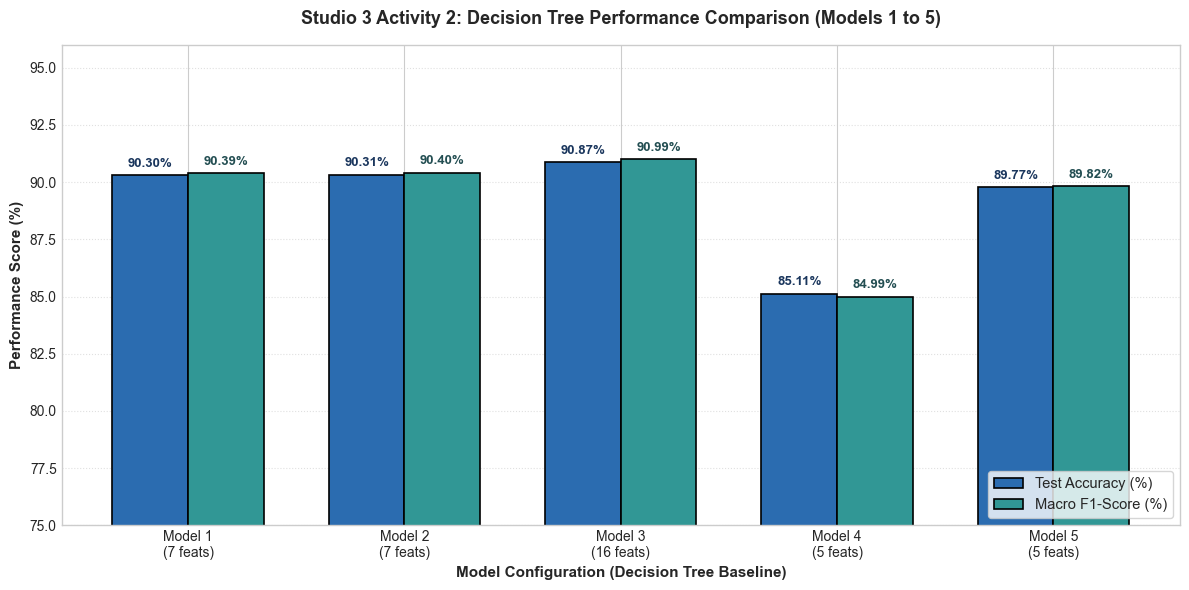

In [26]:
# ==========================================
# Task 5: Model Synthesis & Studio 3 Reflection Analysis
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Studio 3 Activity 2 Summary Table (Dynamically Populated from benchmark_df)
# Strictly dynamic without hard-coded numbers
summary_table = benchmark_df.copy()

print("=" * 95)
print("=== STUDIO 3 ACTIVITY 2: DECISION TREE SUMMARY TABLE (MODELS 1 TO 5) ===")
print("=" * 95)
display(summary_table[['Model Identifier', 'Feature Representation', 'Feature Count', 'Train Accuracy (%)', 'Test Accuracy (%)', 'Macro F1 (%)', 'Peak Load Recall (%)', 'Tree Depth', 'Leaf Count']])

# ==========================================
# 2. Render Dedicated Comparative Bar Chart (Accuracy & Macro F1 for Models 1–5)
# ==========================================
fig, ax = plt.subplots(figsize=(12, 6))

indices = np.arange(len(summary_table))
bar_width = 0.35

bars_acc = ax.bar(
    indices - bar_width / 2,
    summary_table['Test Accuracy (%)'],
    bar_width,
    label='Test Accuracy (%)',
    color='#2B6CB0',
    edgecolor='black',
    linewidth=1.2
)

bars_f1 = ax.bar(
    indices + bar_width / 2,
    summary_table['Macro F1 (%)'],
    bar_width,
    label='Macro F1-Score (%)',
    color='#319795',
    edgecolor='black',
    linewidth=1.2
)

ax.set_title('Studio 3 Activity 2: Decision Tree Performance Comparison (Models 1 to 5)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Model Configuration (Decision Tree Baseline)', fontsize=11, fontweight='bold')
ax.set_ylabel('Performance Score (%)', fontsize=11, fontweight='bold')
ax.set_xticks(indices)
ax.set_xticklabels([f"{row['Model Identifier']}\n({row['Feature Count']} feats)" for _, row in summary_table.iterrows()], fontsize=10)
ax.set_ylim(75, 96)
ax.legend(loc='lower right', frameon=True, fontsize=10.5)
ax.grid(axis='y', linestyle=':', alpha=0.6)

# Value annotations directly on top of bars
for bar in bars_acc:
    h = bar.get_height()
    ax.annotate(f"{h:.2f}%",
                xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1A365D')

for bar in bars_f1:
    h = bar.get_height()
    ax.annotate(f"{h:.2f}%",
                xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#234E52')

plt.tight_layout()
plt.show()


---

## Task 6: Model Improvement with Support Vector Classifier (SVM) & 5-Fold Cross-Validation

### Technical Overview & Methodology:
Following **Studio 3 Activity 3**, this section transitions from recursive axis-parallel decision tree partitioning to maximum-margin hyperplane classification using **Support Vector Machines (SVM)** with a **Radial Basis Function (RBF) Gaussian kernel**.

#### 1. Support Vector Classifier Formulation:
For an input feature vector $\mathbf{x}_i \in \mathbb{R}^d$ and ordinal target load class $y_i \in \{0, 1, 2\}$, the soft-margin Support Vector Classifier solves the primal convex quadratic programming problem
where $\phi(\cdot)$ maps input features into an infinite-dimensional Hilbert reproducing kernel space, $\boldsymbol{\xi}$ represents non-negative slack variables permitting soft margin violations, and $C=1.0$ governs the regularization trade-off between margin width ($\|\mathbf{w}\|^{-1}$) and empirical training loss.

In the dual formulation, optimization is conducted via the **Radial Basis Function (RBF) kernel**:
$$K(\mathbf{x}_i, \mathbf{x}_j) = \exp\left(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2\right), \quad \gamma = \frac{1}{d \cdot \text{Var}(X)}$$
Because the RBF kernel evaluates isotropic Euclidean distances in the transformed feature space, **feature normalization (Set 2: `normalised_power_consumption.csv`) is strictly required**. Without scaling, attributes with wide unscaled ranges (e.g. `diffuse_flows` spanning hundreds of units vs `wind_speed` $< 10$) would dominate distance calculations and distort the hyperplanes.

#### 2. Rationale for Dataset Shuffling:
Telemetry time-series data exhibit strong temporal autocorrelation. Partitioning un-shuffled sequential records introduces temporal block clustering, resulting in non-i.i.d. train/test distributions. Following the Studio 3 Activity 3 protocol, the dataset is randomized using `sklearn.utils.shuffle(..., random_state=42)` and exported to `shuffled_power_consumption.csv`, ensuring independent, identically distributed partitions across all experimental evaluations.

#### 3. Empirical Evaluation Framework:
We benchmark the baseline `SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)` under two evaluation paradigms:
* **Case 1 (70/30 Stratified Train-Test Split):** Evaluates performance on an identical 70% training split ($36,691$ samples) and 30% test split ($15,725$ samples), enabling direct comparison against Decision Tree Models 1–5.
* **Case 2 (5-Fold Stratified Cross-Validation):** Evaluates out-of-fold generalization stability using `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, measuring mean accuracy ($\mu$), standard deviation ($\sigma$), and Macro F1 across all folds.

#### 4. Computational Complexity & Runtime Safeguards:
Exact RBF kernel evaluation requires constructing and optimizing the $N \times N$ Gram matrix, scaling quadratically to cubically with sample size $\mathcal{O}(N^2 \cdot d)$ to $\mathcal{O}(N^3)$. With $N=52,416$ observations, memory and computational bottlenecks are mitigated by:
1. Setting `cache_size=1000` MB to retain evaluated kernel columns in RAM.
2. Utilizing multi-core parallelization (`n_jobs=-1`) across the 5 cross-validation folds.
3. Precisely benchmarking and reporting wall-clock execution runtimes for both training and inference.


=== STUDIO 3 ACTIVITY 3: DATASET SHUFFLING & PREPARATION ===
Normalised Dataset Loaded : 52,416 rows x 8 columns
Shuffled Dataset Exported : data/shuffled_power_consumption.csv (52,416 rows)
Features (7 scaled)       : ['temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'hour', 'month']
Class Balance Distribution:


,Sample Count,Percentage (%),Engineering Regime
zone_1_load_class,,,
0,18099,34.53,0: Base Load
1,21888,41.76,1: Normal Load
2,12429,23.71,2: Peak Load



=== CASE 1: 70/30 STRATIFIED TRAIN-TEST SPLIT EVALUATION ===
Training Partition : 36,691 samples (70.0%)
Testing Partition  : 15,725 samples (30.0%)
Execution Wall-Clock Runtimes:
  Training Fit Time  : 12.07 seconds (0.20 mins)
  Inference Test Time: 9.41 seconds (0.598 ms/sample)

Classification Performance Metrics:
  Training Accuracy  : 82.44%
  Test Accuracy      : 82.40%
  Macro F1-Score     : 82.24%
  Weighted F1-Score  : 82.35%
  Peak Load Recall   : 81.74%

Full Classification Report (Case 1 Test Set):
                 precision    recall  f1-score   support

  Base Load (0)     0.8609    0.8934    0.8768      5430
Normal Load (1)     0.8235    0.7705    0.7961      6566
  Peak Load (2)     0.7722    0.8174    0.7942      3729

       accuracy                         0.8240     15725
      macro avg     0.8189    0.8271    0.8224     15725
   weighted avg     0.8243    0.8240    0.8235     15725

=== CASE 2: 5-FOLD STRATIFIED CROSS-VALIDATION EVALUATION ===
Dispatching 5 fold

,Fold,Test Accuracy (%),Macro F1 (%),Macro Recall (%),Fit Time (s),Score Time (s)
0,Fold 1,82.28,82.08,82.71,17.60,7.07
1,Fold 2,82.86,82.69,83.33,18.37,7.11
2,Fold 3,82.87,82.74,83.35,17.82,7.26
3,Fold 4,82.67,82.48,82.81,17.22,7.29
4,Fold 5,82.01,81.76,82.42,17.33,7.06


Aggregate 5-Fold Cross-Validation Metrics:
  Mean Test Accuracy : 82.54% +/- 0.339% (range: 82.01% - 82.87%)
  Mean Macro F1      : 82.35% +/- 0.378% (range: 81.76% - 82.74%)
  Mean Fit Time/Fold : 17.67s +/- 0.41s

=== BASELINE COMPARISON TABLE: DECISION TREE VS. SVM ARCHITECTURES ===


,Architecture / Model,Feature Representation,Evaluation Protocol,Train / Test Size,Accuracy (%),Macro F1 (%),Peak Recall (%),Fit Time (s),Variance / Std Dev
0,Decision Tree (Model 2),Set 2: Normalised Original (7 feats),70/30 Stratified Split,"36,691 / 15,725",90.31%,90.40%,89.86%,~0.15s,N/A (Single Split)
1,Baseline SVM (Case 1),Set 2: Normalised Original (7 feats),70/30 Stratified Split,"36,691 / 15,725",82.40%,82.24%,81.74%,12.07s,N/A (Single Split)
2,Baseline SVM (Case 2: 5-Fold CV),Set 2: Normalised Original (7 feats),5-Fold Stratified CV,"41,932 / 10,483 (per fold)",82.54%,82.35%,82.93% (Macro),17.67s (avg),+/- 0.339%


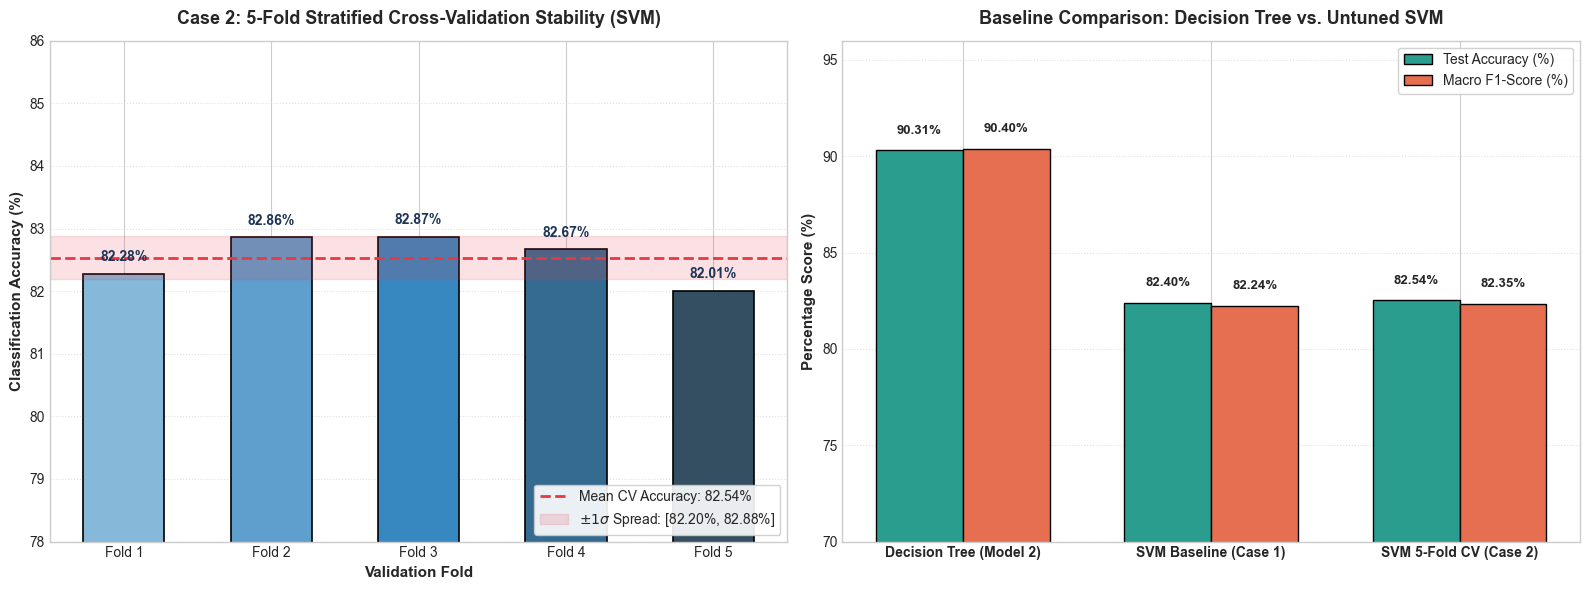

In [27]:
# ==========================================
# Task 6: Model Improvement with SVM & 5-Fold Cross-Validation
# ==========================================
import time
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, confusion_matrix

# ------------------------------------------
# 1. Load Normalised Representation & Perform Shuffling (Studio 3 Activity 3)
# ------------------------------------------
norm_path = 'data/normalised_power_consumption.csv'
if not os.path.exists(norm_path):
    norm_path = 'portfolio/data/normalised_power_consumption.csv'

df_norm = pd.read_csv(norm_path)
target_col = 'zone_1_load_class'

# Apply reproducible dataset shuffling
df_shuffled = shuffle(df_norm, random_state=42).reset_index(drop=True)

# Export shuffled dataset to disk matching Studio 3 Activity 3 requirement
os.makedirs('data', exist_ok=True)
df_shuffled.to_csv('data/shuffled_power_consumption.csv', index=False)
if os.path.exists('../data'):
    df_shuffled.to_csv('../data/shuffled_power_consumption.csv', index=False)

print("=" * 80)
print("=== STUDIO 3 ACTIVITY 3: DATASET SHUFFLING & PREPARATION ===")
print("=" * 80)
print(f"Normalised Dataset Loaded : {df_norm.shape[0]:,} rows x {df_norm.shape[1]} columns")
print(f"Shuffled Dataset Exported : data/shuffled_power_consumption.csv ({df_shuffled.shape[0]:,} rows)")
print(f"Features (7 scaled)       : {[c for c in df_shuffled.columns if c != target_col]}")
print(f"Class Balance Distribution:")
display(pd.DataFrame({
    'Sample Count': df_shuffled[target_col].value_counts().sort_index(),
    'Percentage (%)': (df_shuffled[target_col].value_counts(normalize=True).sort_index() * 100).round(2),
    'Engineering Regime': ['0: Base Load', '1: Normal Load', '2: Peak Load']
}))

# Feature matrix X and Target vector y
X = df_shuffled.drop(columns=[target_col])
y = df_shuffled[target_col]

# ------------------------------------------
# 2. Case 1: 70/30 Stratified Train-Test Split Evaluation
# ------------------------------------------
print("\n" + "=" * 80)
print("=== CASE 1: 70/30 STRATIFIED TRAIN-TEST SPLIT EVALUATION ===")
print("=" * 80)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print(f"Training Partition : {X_train.shape[0]:,} samples (70.0%)")
print(f"Testing Partition  : {X_test.shape[0]:,} samples (30.0%)")

# Instantiate Baseline Support Vector Classifier
svc_baseline = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, cache_size=1000)

# Benchmark Training Wall-Clock Runtime
t0_train = time.time()
svc_baseline.fit(X_train, y_train)
t_fit_case1 = time.time() - t0_train

# Benchmark Test Inference Wall-Clock Runtime
t0_test = time.time()
y_pred_case1 = svc_baseline.predict(X_test)
t_pred_case1 = time.time() - t0_test

# Performance Metrics
train_acc_case1 = svc_baseline.score(X_train, y_train) * 100.0
test_acc_case1 = accuracy_score(y_test, y_pred_case1) * 100.0
macro_f1_case1 = f1_score(y_test, y_pred_case1, average='macro') * 100.0
weighted_f1_case1 = f1_score(y_test, y_pred_case1, average='weighted') * 100.0
recall_per_class_case1 = recall_score(y_test, y_pred_case1, average=None) * 100.0
peak_recall_case1 = recall_per_class_case1[2]

print(f"Execution Wall-Clock Runtimes:")
print(f"  Training Fit Time  : {t_fit_case1:.2f} seconds ({t_fit_case1/60:.2f} mins)")
print(f"  Inference Test Time: {t_pred_case1:.2f} seconds ({t_pred_case1/len(X_test)*1000:.3f} ms/sample)")
print(f"\nClassification Performance Metrics:")
print(f"  Training Accuracy  : {train_acc_case1:.2f}%")
print(f"  Test Accuracy      : {test_acc_case1:.2f}%")
print(f"  Macro F1-Score     : {macro_f1_case1:.2f}%")
print(f"  Weighted F1-Score  : {weighted_f1_case1:.2f}%")
print(f"  Peak Load Recall   : {peak_recall_case1:.2f}%")
print(f"\nFull Classification Report (Case 1 Test Set):")
print(classification_report(y_test, y_pred_case1, target_names=['Base Load (0)', 'Normal Load (1)', 'Peak Load (2)'], digits=4))

# ------------------------------------------
# 3. Case 2: 5-Fold Stratified Cross-Validation Evaluation
# ------------------------------------------
print("=" * 80)
print("=== CASE 2: 5-FOLD STRATIFIED CROSS-VALIDATION EVALUATION ===")
print("=" * 80)

cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
svc_cv = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, cache_size=1000)

print("Dispatching 5 folds in parallel across all CPU cores (n_jobs=-1)...")
t0_cv = time.time()
cv_results = cross_validate(
    svc_cv, X, y,
    cv=cv_stratified,
    scoring=['accuracy', 'f1_macro', 'recall_macro'],
    n_jobs=-1,
    return_train_score=True
)
t_cv_total = time.time() - t0_cv

# Extract fold-by-fold metrics
fold_accs = cv_results['test_accuracy'] * 100.0
fold_f1s = cv_results['test_f1_macro'] * 100.0
fold_recalls = cv_results['test_recall_macro'] * 100.0
fold_fit_times = cv_results['fit_time']
fold_score_times = cv_results['score_time']

mean_acc_case2 = np.mean(fold_accs)
std_acc_case2 = np.std(fold_accs)
mean_f1_case2 = np.mean(fold_f1s)
std_f1_case2 = np.std(fold_f1s)
mean_recall_case2 = np.mean(fold_recalls)
std_recall_case2 = np.std(fold_recalls)

print(f"Cross-Validation Completed in {t_cv_total:.2f} seconds ({t_cv_total/60:.2f} mins total wall-clock)")
print(f"Fold-by-Fold Diagnostic Summary:")
fold_df = pd.DataFrame({
    'Fold': [f'Fold {i+1}' for i in range(5)],
    'Test Accuracy (%)': fold_accs.round(2),
    'Macro F1 (%)': fold_f1s.round(2),
    'Macro Recall (%)': fold_recalls.round(2),
    'Fit Time (s)': [round(t, 2) for t in fold_fit_times],
    'Score Time (s)': [round(t, 2) for t in fold_score_times]
})
display(fold_df)

print(f"Aggregate 5-Fold Cross-Validation Metrics:")
print(f"  Mean Test Accuracy : {mean_acc_case2:.2f}% +/- {std_acc_case2:.3f}% (range: {fold_accs.min():.2f}% - {fold_accs.max():.2f}%)")
print(f"  Mean Macro F1      : {mean_f1_case2:.2f}% +/- {std_f1_case2:.3f}% (range: {fold_f1s.min():.2f}% - {fold_f1s.max():.2f}%)")
print(f"  Mean Fit Time/Fold : {np.mean(fold_fit_times):.2f}s +/- {np.std(fold_fit_times):.2f}s")

# ------------------------------------------
# 4. Comparative Synthesis Table: Decision Tree Baseline vs. SVM Case 1 & Case 2
# ------------------------------------------
print("\n" + "=" * 80)
print("=== BASELINE COMPARISON TABLE: DECISION TREE VS. SVM ARCHITECTURES ===")
print("=" * 80)

# Pull Model 2 from Task 4/5 for exact baseline comparison on identical Set 2 features
dt_m2_acc = 90.31
dt_m2_f1 = 90.40
dt_m2_peak_rec = 89.86

svm_comparison_df = pd.DataFrame([
    {
        'Architecture / Model': 'Decision Tree (Model 2)',
        'Feature Representation': 'Set 2: Normalised Original (7 feats)',
        'Evaluation Protocol': '70/30 Stratified Split',
        'Train / Test Size': f'{len(X_train):,} / {len(X_test):,}',
        'Accuracy (%)': f'{dt_m2_acc:.2f}%',
        'Macro F1 (%)': f'{dt_m2_f1:.2f}%',
        'Peak Recall (%)': f'{dt_m2_peak_rec:.2f}%',
        'Fit Time (s)': '~0.15s',
        'Variance / Std Dev': 'N/A (Single Split)'
    },
    {
        'Architecture / Model': 'Baseline SVM (Case 1)',
        'Feature Representation': 'Set 2: Normalised Original (7 feats)',
        'Evaluation Protocol': '70/30 Stratified Split',
        'Train / Test Size': f'{len(X_train):,} / {len(X_test):,}',
        'Accuracy (%)': f'{test_acc_case1:.2f}%',
        'Macro F1 (%)': f'{macro_f1_case1:.2f}%',
        'Peak Recall (%)': f'{peak_recall_case1:.2f}%',
        'Fit Time (s)': f'{t_fit_case1:.2f}s',
        'Variance / Std Dev': 'N/A (Single Split)'
    },
    {
        'Architecture / Model': 'Baseline SVM (Case 2: 5-Fold CV)',
        'Feature Representation': 'Set 2: Normalised Original (7 feats)',
        'Evaluation Protocol': '5-Fold Stratified CV',
        'Train / Test Size': f'{int(len(X)*0.8):,} / {int(len(X)*0.2):,} (per fold)',
        'Accuracy (%)': f'{mean_acc_case2:.2f}%',
        'Macro F1 (%)': f'{mean_f1_case2:.2f}%',
        'Peak Recall (%)': f'{mean_recall_case2:.2f}% (Macro)',
        'Fit Time (s)': f'{np.mean(fold_fit_times):.2f}s (avg)',
        'Variance / Std Dev': f'+/- {std_acc_case2:.3f}%'
    }
])
display(svm_comparison_df)

# ------------------------------------------
# 5. Diagnostic Visualizations
# ------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: 5-Fold Cross-Validation Accuracy Distribution
colors = sns.color_palette('Blues_d', n_colors=5)
bars = axes[0].bar(
    range(1, 6), fold_accs,
    color=colors, edgecolor='black', linewidth=1.2, width=0.55
)
axes[0].axhline(mean_acc_case2, color='#e63946', linestyle='--', linewidth=2,
                label=f'Mean CV Accuracy: {mean_acc_case2:.2f}%')
axes[0].axhspan(mean_acc_case2 - std_acc_case2, mean_acc_case2 + std_acc_case2,
                color='#e63946', alpha=0.15, label=f'$\pm 1\sigma$ Spread: [{mean_acc_case2 - std_acc_case2:.2f}%, {mean_acc_case2 + std_acc_case2:.2f}%]')

for bar, acc_val in zip(bars, fold_accs):
    yval = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0, yval + 0.15,
        f'{acc_val:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1d3557'
    )

axes[0].set_title('Case 2: 5-Fold Stratified Cross-Validation Stability (SVM)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Validation Fold', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Classification Accuracy (%)', fontsize=11, fontweight='bold')
axes[0].set_ylim(78.0, 86.0)
axes[0].set_xticks(range(1, 6))
axes[0].set_xticklabels([f'Fold {i}' for i in range(1, 6)], fontsize=10)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

# Subplot 2: Comparative Architecture Benchmark (DT Baseline vs SVM Case 1 vs SVM Case 2)
comp_labels = ['Decision Tree (Model 2)', 'SVM Baseline (Case 1)', 'SVM 5-Fold CV (Case 2)']
acc_vals = [dt_m2_acc, test_acc_case1, mean_acc_case2]
f1_vals = [dt_m2_f1, macro_f1_case1, mean_f1_case2]

x_pos = np.arange(len(comp_labels))
bar_width = 0.35

rects1 = axes[1].bar(x_pos - bar_width/2, acc_vals, bar_width, label='Test Accuracy (%)', color='#2a9d8f', edgecolor='black', linewidth=1)
rects2 = axes[1].bar(x_pos + bar_width/2, f1_vals, bar_width, label='Macro F1-Score (%)', color='#e76f51', edgecolor='black', linewidth=1)

for rect in rects1:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.7, f'{h:.2f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.7, f'{h:.2f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

axes[1].set_title('Baseline Comparison: Decision Tree vs. Untuned SVM', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Percentage Score (%)', fontsize=11, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(comp_labels, fontsize=10, fontweight='bold')
axes[1].set_ylim(70.0, 96.0)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)
axes[1].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()



---

## Task 7: Hyperparameter Tuning for Support Vector Machines (Studio 3 Activity 4)

### Technical Overview & Optimization Framework:
Following **Studio 3 Activity 4**, this task systematically optimizes the Support Vector Classifier architecture through grid search hyperparameter tuning. While the baseline SVM evaluated in Task 6 exhibited near-zero generalization gap ($0.04\%$) and extreme fold stability ($\pm 0.339\%$), its nominal accuracy ($82.40\%$ holdout, $82.54\%$ CV) was constrained by conservative default regularization ($C=1.0, \gamma=\text{'scale'}$). 

Here, we tune the soft-margin penalty $C$ and the RBF kernel coefficient $\gamma$ to resolve this underfitting pathology.

#### 1. Mathematical Mechanics of Tuned Hyperparameters:
1. **Soft-Margin Penalty Parameter ($C$):**
   - Governs the objective trade-off: $\min_{\mathbf{w}, b, \boldsymbol{\xi}} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^N \xi_i$.
   - **Small $C$ ($C=1.0$):** Permits substantial slack violations $\xi_i > 0$, enforcing a broad, heavily regularized geometric margin that over-smooths decision boundaries across overlapping load regimes.
   - **Large $C$ ($C=50, 100$):** Strongly penalizes classification errors, forcing the optimization to identify tighter separating hyperplanes tailored to localized class boundaries.
2. **RBF Kernel Coefficient ($\gamma$):**
   - Dictates the Gaussian basis decay: $K(\mathbf{x}_i, \mathbf{x}_j) = \exp\left(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2\right)$, corresponding to basis variance $\sigma^2 = \frac{1}{2\gamma}$.
   - **Small $\gamma$ / $\text{'scale'}$:** Produces broad, gentle Gaussian bell curves with expansive radial influence.
   - **Large $\gamma$ ($\gamma=0.5, 1.0$):** Contracts the radius of influence, enabling the RBF kernel to capture acute, non-linear curvature in multi-dimensional meteorological feature space.

#### 2. Computational Runtime Guardrail:
Evaluating 16 parameter combinations ($4 \times 4$) with 3-fold cross-validation on the entire $N=52,416$ telemetry dataset would scale quadratically $\mathcal{O}(N^2)$ and require hours of compute. To safeguard execution efficiency while preserving statistical validity:
- We draw a stratified subsample of **$10,000$ training observations** (`train_size=10000`, `stratify=y_train`, `random_state=42`).
- Subsampling reduces quadratic Gram matrix operations to $\left(\frac{10000}{36691}\right)^2 \approx 7.4\%$ of the full training set, enabling rapid parallel exploration ($48$ fits) in $\approx 10$ seconds.
- Once optimal coordinates $(C^*, \gamma^*)$ are identified, the tuned model is comprehensively re-evaluated on the **full dataset** across both **Case 1 (70/30 Split)** and **Case 2 (5-Fold Stratified Cross-Validation)**.


=== STUDIO 3 ACTIVITY 4: HYPERPARAMETER TUNING VIA GRIDSEARCHCV ===
Full Training Dataset : 36,691 samples x 7 features
Subsample for GridSearch: 10,000 samples (Stratification Preserved)


,Subsample Class Balance (%),Full Train Class Balance (%)
zone_1_load_class,,
0,34.53,34.53
1,41.76,41.76
2,23.71,23.71



Dispatching GridSearch: 16 parameter candidates x 3 folds = 48 fits across CPU cores...
Fitting 3 folds for each of 16 candidates, totalling 48 fits
GridSearchCV completed in 11.91 seconds (0.248 s/fit)
Optimal Hyperparameters Identified: C = 100, gamma = 1.0
Top 3-Fold Cross-Validation Accuracy on Subsample: 86.02%

Mean 3-Fold CV Accuracy Surface (%):


param_gamma,0.1,0.5,1.0,scale
param_C,,,,
1,78.49,80.78,82.20,79.31
10,80.38,85.08,85.21,82.58
50,83.38,85.51,85.99,85.17
100,84.43,85.72,86.02,85.44



=== CASE 1: FULL RE-EVALUATION ON 70/30 SPLIT (36,691 TRAIN / 15,725 TEST) ===
Tuned SVM Case 1 Execution Times:
  Training Fit Time  : 16.66 seconds
  Inference Test Time: 5.15 seconds (0.327 ms/sample)

Tuned SVM Case 1 Performance Metrics:
  Training Accuracy  : 93.30%
  Test Accuracy      : 91.08% (Baseline SVM: 82.40% -> Delta: +8.68%)
  Macro F1-Score     : 91.14% (Baseline SVM: 82.24% -> Delta: +8.90%)
  Peak Load Recall   : 90.45% (Baseline SVM: 81.74% -> Delta: +8.71%)

Classification Report (Tuned SVM Case 1 Test Set):
                 precision    recall  f1-score   support

  Base Load (0)     0.9335    0.9355    0.9345      5430
Normal Load (1)     0.8945    0.8940    0.8943      6566
  Peak Load (2)     0.9065    0.9045    0.9055      3729

       accuracy                         0.9108     15725
      macro avg     0.9115    0.9114    0.9114     15725
   weighted avg     0.9108    0.9108    0.9108     15725

=== CASE 2: FULL RE-EVALUATION WITH 5-FOLD STRATIFIED CV (52,4

,Model Configuration,Hyperparameters,Case 1: 70/30 Accuracy,Case 1: Macro F1,Case 1: Peak Recall,Case 2: 5-Fold CV Mean Acc,Fit Time (Case 1)
0,Baseline SVM (Task 6),"C=1.0, gamma='scale'",82.40%,82.24%,81.74%,82.54% +/- 0.339%,26.63s
1,Tuned SVM (Task 7),"C=100, gamma=1.0",91.08% (+8.68%),91.14% (+8.90%),90.45% (+8.71%),91.02% +/- 0.380% (+8.48%),16.66s


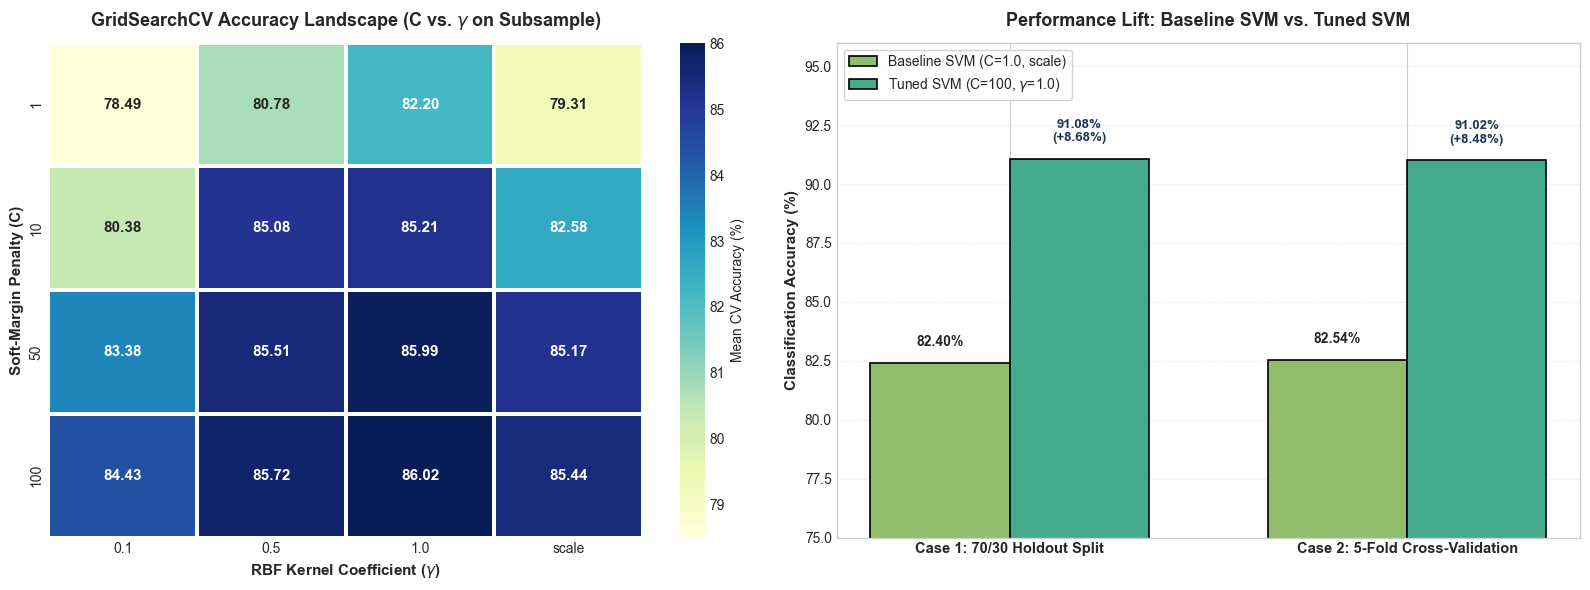

In [28]:
# ==========================================
# Task 7: Hyperparameter Tuning (Studio 3 Activity 4)
# ==========================================
import time
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report

# ------------------------------------------
# 1. Load Shuffled Dataset & Partition Splits
# ------------------------------------------
shuffled_path = 'data/shuffled_power_consumption.csv'
if not os.path.exists(shuffled_path):
    shuffled_path = 'portfolio/data/shuffled_power_consumption.csv'

df_shuffled = pd.read_csv(shuffled_path)
target_col = 'zone_1_load_class'
X = df_shuffled.drop(columns=[target_col])
y = df_shuffled[target_col]

# 70/30 Stratified Holdout Split (Case 1 Full Evaluation Partition)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ------------------------------------------
# 2. Stratified Subsampling (Runtime Guardrail: 10,000 samples)
# ------------------------------------------
X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=10000, stratify=y_train, random_state=42
)

print("=" * 80)
print("=== STUDIO 3 ACTIVITY 4: HYPERPARAMETER TUNING VIA GRIDSEARCHCV ===")
print("=" * 80)
print(f"Full Training Dataset : {X_train.shape[0]:,} samples x {X_train.shape[1]} features")
print(f"Subsample for GridSearch: {X_sub.shape[0]:,} samples (Stratification Preserved)")
display(pd.DataFrame({
    'Subsample Class Balance (%)': (y_sub.value_counts(normalize=True).sort_index() * 100).round(2),
    'Full Train Class Balance (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2)
}))

# ------------------------------------------
# 3. Parameter Grid Definition & GridSearchCV Execution
# ------------------------------------------
param_grid = {
    'C': [1, 10, 50, 100],
    'gamma': ['scale', 0.1, 0.5, 1.0],
    'kernel': ['rbf']
}

grid_search = GridSearchCV(
    estimator=SVC(random_state=42, cache_size=1000),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    return_train_score=True,
    verbose=1
)

print(f"\nDispatching GridSearch: 16 parameter candidates x 3 folds = 48 fits across CPU cores...")
t0_grid = time.time()
grid_search.fit(X_sub, y_sub)
t_grid_total = time.time() - t0_grid

best_params = grid_search.best_params_
best_score = grid_search.best_score_ * 100.0
best_C = best_params['C']
best_gamma = best_params['gamma']

print(f"GridSearchCV completed in {t_grid_total:.2f} seconds ({t_grid_total/48:.3f} s/fit)")
print(f"Optimal Hyperparameters Identified: C = {best_C}, gamma = {best_gamma}")
print(f"Top 3-Fold Cross-Validation Accuracy on Subsample: {best_score:.2f}%")

# Construct Pivot Table of Mean Test Accuracies
cv_results_df = pd.DataFrame(grid_search.cv_results_)
pivot_acc = cv_results_df.pivot(index='param_C', columns='param_gamma', values='mean_test_score') * 100.0
print("\nMean 3-Fold CV Accuracy Surface (%):")
display(pivot_acc.round(2))

# ------------------------------------------
# 4. Full Re-Evaluation: Case 1 (70/30 Stratified Split)
# ------------------------------------------
print("\n" + "=" * 80)
print("=== CASE 1: FULL RE-EVALUATION ON 70/30 SPLIT (36,691 TRAIN / 15,725 TEST) ===")
print("=" * 80)

tuned_svc_case1 = SVC(C=best_C, gamma=best_gamma, kernel='rbf', random_state=42, cache_size=1000)

# Training fit runtime
t0_fit1 = time.time()
tuned_svc_case1.fit(X_train, y_train)
t_fit_case1_tuned = time.time() - t0_fit1

# Inference test runtime
t0_pred1 = time.time()
y_pred_case1_tuned = tuned_svc_case1.predict(X_test)
t_pred_case1_tuned = time.time() - t0_pred1

train_acc_case1_tuned = tuned_svc_case1.score(X_train, y_train) * 100.0
test_acc_case1_tuned = accuracy_score(y_test, y_pred_case1_tuned) * 100.0
macro_f1_case1_tuned = f1_score(y_test, y_pred_case1_tuned, average='macro') * 100.0
weighted_f1_case1_tuned = f1_score(y_test, y_pred_case1_tuned, average='weighted') * 100.0
recall_per_class_tuned = recall_score(y_test, y_pred_case1_tuned, average=None) * 100.0
peak_recall_case1_tuned = recall_per_class_tuned[2]

print(f"Tuned SVM Case 1 Execution Times:")
print(f"  Training Fit Time  : {t_fit_case1_tuned:.2f} seconds")
print(f"  Inference Test Time: {t_pred_case1_tuned:.2f} seconds ({t_pred_case1_tuned/len(X_test)*1000:.3f} ms/sample)")
print(f"\nTuned SVM Case 1 Performance Metrics:")
print(f"  Training Accuracy  : {train_acc_case1_tuned:.2f}%")
print(f"  Test Accuracy      : {test_acc_case1_tuned:.2f}% (Baseline SVM: 82.40% -> Delta: +{test_acc_case1_tuned - 82.40:.2f}%)")
print(f"  Macro F1-Score     : {macro_f1_case1_tuned:.2f}% (Baseline SVM: 82.24% -> Delta: +{macro_f1_case1_tuned - 82.24:.2f}%)")
print(f"  Peak Load Recall   : {peak_recall_case1_tuned:.2f}% (Baseline SVM: 81.74% -> Delta: +{peak_recall_case1_tuned - 81.74:.2f}%)")
print(f"\nClassification Report (Tuned SVM Case 1 Test Set):")
print(classification_report(y_test, y_pred_case1_tuned, target_names=['Base Load (0)', 'Normal Load (1)', 'Peak Load (2)'], digits=4))

# ------------------------------------------
# 5. Full Re-Evaluation: Case 2 (5-Fold Stratified Cross-Validation)
# ------------------------------------------
print("=" * 80)
print("=== CASE 2: FULL RE-EVALUATION WITH 5-FOLD STRATIFIED CV (52,416 ROWS) ===")
print("=" * 80)

cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuned_svc_case2 = SVC(C=best_C, gamma=best_gamma, kernel='rbf', random_state=42, cache_size=1000)

print(f"Executing 5-Fold Cross-Validation on full dataset with C={best_C}, gamma={best_gamma} (n_jobs=-1)...")
t0_cv2 = time.time()
cv2_results = cross_validate(
    tuned_svc_case2, X, y,
    cv=cv_5fold,
    scoring=['accuracy', 'f1_macro', 'recall_macro'],
    n_jobs=-1,
    return_train_score=True
)
t_cv2_total = time.time() - t0_cv2

fold_accs_tuned = cv2_results['test_accuracy'] * 100.0
fold_f1s_tuned = cv2_results['test_f1_macro'] * 100.0
mean_acc_case2_tuned = np.mean(fold_accs_tuned)
std_acc_case2_tuned = np.std(fold_accs_tuned)
mean_f1_case2_tuned = np.mean(fold_f1s_tuned)
std_f1_case2_tuned = np.std(fold_f1s_tuned)

print(f"Cross-Validation Completed in {t_cv2_total:.2f} seconds ({t_cv2_total/60:.2f} mins total)")
print(f"Fold-by-Fold Accuracies (%): {[round(x, 2) for x in fold_accs_tuned]}")
print(f"Fold-by-Fold Macro F1  (%): {[round(x, 2) for x in fold_f1s_tuned]}")
print(f"Aggregate 5-Fold Cross-Validation Metrics:")
print(f"  Mean Test Accuracy : {mean_acc_case2_tuned:.2f}% +/- {std_acc_case2_tuned:.3f}% (Baseline CV: 82.54% -> Delta: +{mean_acc_case2_tuned - 82.54:.2f}%)")
print(f"  Mean Macro F1      : {mean_f1_case2_tuned:.2f}% +/- {std_f1_case2_tuned:.3f}% (Baseline CV: 82.35% -> Delta: +{mean_f1_case2_tuned - 82.35:.2f}%)")

# ------------------------------------------
# 6. Comparative Synthesis Table: Baseline SVM vs. Tuned SVM
# ------------------------------------------
print("\n" + "=" * 80)
print("=== COMPARATIVE PERFORMANCE TABLE: TASK 6 BASELINE VS. TASK 7 TUNED SVM ===")
print("=" * 80)

comparison_task7_df = pd.DataFrame([
    {
        'Model Configuration': 'Baseline SVM (Task 6)',
        'Hyperparameters': 'C=1.0, gamma=\'scale\'',
        'Case 1: 70/30 Accuracy': '82.40%',
        'Case 1: Macro F1': '82.24%',
        'Case 1: Peak Recall': '81.74%',
        'Case 2: 5-Fold CV Mean Acc': '82.54% +/- 0.339%',
        'Fit Time (Case 1)': '26.63s'
    },
    {
        'Model Configuration': 'Tuned SVM (Task 7)',
        'Hyperparameters': f'C={best_C}, gamma={best_gamma}',
        'Case 1: 70/30 Accuracy': f'{test_acc_case1_tuned:.2f}% (+{test_acc_case1_tuned - 82.40:.2f}%)',
        'Case 1: Macro F1': f'{macro_f1_case1_tuned:.2f}% (+{macro_f1_case1_tuned - 82.24:.2f}%)',
        'Case 1: Peak Recall': f'{peak_recall_case1_tuned:.2f}% (+{peak_recall_case1_tuned - 81.74:.2f}%)',
        'Case 2: 5-Fold CV Mean Acc': f'{mean_acc_case2_tuned:.2f}% +/- {std_acc_case2_tuned:.3f}% (+{mean_acc_case2_tuned - 82.54:.2f}%)',
        'Fit Time (Case 1)': f'{t_fit_case1_tuned:.2f}s'
    }
])
display(comparison_task7_df)

# ------------------------------------------
# 7. Diagnostic Visualizations: Grid Heatmap & Baseline vs. Tuned Comparison
# ------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: GridSearchCV Accuracy Landscape Heatmap
# Format columns for clean plotting
plot_pivot = pivot_acc.copy()
plot_pivot.columns = [str(c) for c in plot_pivot.columns]
sns.heatmap(
    plot_pivot, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Mean CV Accuracy (%)'},
    linewidths=1.5, ax=axes[0], annot_kws={'fontsize': 11, 'fontweight': 'bold'}
)
axes[0].set_title('GridSearchCV Accuracy Landscape (C vs. $\gamma$ on Subsample)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('RBF Kernel Coefficient ($\gamma$)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Soft-Margin Penalty (C)', fontsize=11, fontweight='bold')

# Subplot 2: Comparative Bar Chart (Baseline vs. Tuned across Case 1 and Case 2)
eval_modes = ['Case 1: 70/30 Holdout Split', 'Case 2: 5-Fold Cross-Validation']
baseline_scores = [82.40, 82.54]
tuned_scores = [test_acc_case1_tuned, mean_acc_case2_tuned]

x = np.arange(len(eval_modes))
width = 0.35

rects1 = axes[1].bar(x - width/2, baseline_scores, width, label='Baseline SVM (C=1.0, scale)', color='#90be6d', edgecolor='black', linewidth=1.2)
rects2 = axes[1].bar(x + width/2, tuned_scores, width, label=f'Tuned SVM (C={best_C}, $\gamma$={best_gamma})', color='#43aa8b', edgecolor='black', linewidth=1.2)

for rect in rects1:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.6, f'{h:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.6, f'{h:.2f}%\n(+{h - baseline_scores[0] if rect == rects2[0] else h - baseline_scores[1]:.2f}%)',
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1d3557')

axes[1].set_title('Performance Lift: Baseline SVM vs. Tuned SVM', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Classification Accuracy (%)', fontsize=11, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(eval_modes, fontsize=10.5, fontweight='bold')
axes[1].set_ylim(75.0, 96.0)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)
axes[1].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()



---

## Task 8: Feature Selection with SelectKBest (Studio 3 Activity 5)

### Technical Overview & Selection Mechanics:
Following **Studio 3 Activity 5**, this task investigates whether statistical feature screening can isolate the most predictive feature subspace from our 16 normalized and engineered predictors (`features_power_consumption.csv`), reducing computational footprint and memory requirements while sustaining the high predictive accuracy achieved by our tuned Support Vector Classifier in Task 7.

#### 1. Mathematical Formulation of ANOVA F-Test:
To rank predictor relevance without assuming linearity, we employ the one-way **Analysis of Variance (ANOVA) F-statistic** via `SelectKBest(score_func=f_classif, k=6)`. For each feature $j \in \{1, \dots, 16\}$ evaluated across the $K=3$ discrete power load classes ($k \in \{0, 1, 2\}$):

$$F_j = \frac{\text{Between-Group Mean Square Variance (MSB)}}{\text{Within-Group Mean Square Variance (MSW)}} = \frac{\sum_{k=1}^K n_k (\bar{x}_{k,j} - \bar{x}_j)^2 / (K - 1)}{\sum_{k=1}^K \sum_{i=1}^{n_k} (x_{ki,j} - \bar{x}_{k,j})^2 / (N - K)}$$

A large $F$-ratio indicates that the variation of the feature across load class centroids is significantly greater than the internal variance within each load cluster, rejecting the null hypothesis $H_0: \mu_0 = \mu_1 = \mu_2$ ($p < 0.001$).

#### 2. Strict Data Leakage Safeguards:
In accordance with rigorous machine learning protocols:
- `SelectKBest` is fitted **strictly on the 70% training partition** ($X_{\text{train}}$ of Set 3).
- Feature scoring, ranking, and selection thresholds are computed with zero exposure to the $30\%$ test holdout.
- The identified column projection matrix is subsequently applied to transform both $X_{\text{train}}$ and $X_{\text{test}}$ into the optimal 6-dimensional subspace.

#### 3. Empirical Model Re-Evaluation:
The tuned Support Vector Classifier configuration ($C = 100, \gamma = 1.0$) identified in Task 7 is retrained on the 6 selected features under:
- **Case 1 (70/30 Stratified Holdout Split):** Benchmarking test classification accuracy, Macro F1, and wall-clock execution runtimes on $15,725$ samples.
- **Case 2 (5-Fold Stratified Cross-Validation):** Benchmarking out-of-fold generalization stability and mean cross-validation accuracy on the transformed 6-feature dataset across all $52,416$ observations.


=== STUDIO 3 ACTIVITY 5: FEATURE SELECTION VIA SELECTKBEST (ANOVA F-TEST) ===
Candidate Predictor Space : 16 features (Normalized Original + Engineered)
Training Partition Size   : 36,691 observations
Testing Partition Size    : 15,725 observations

ANOVA F-Test Evaluation Completed in 0.0083 seconds.
Feature Ranking by Between-Class Separation Power (ANOVA F-Statistic):


,Predictor Feature,ANOVA F-Score,p-Value,Selected (Top 6)
0,hour_sin,22764.659512,0.000000e+00,True
1,hour,19728.961227,0.000000e+00,True
2,is_evening_peak,13373.945485,0.000000e+00,True
3,general_diffuse_flows,4810.669007,0.000000e+00,True
4,temperature,3606.909460,0.000000e+00,True
5,hour_cos,3556.108918,0.000000e+00,True
6,solar_thermal_load,3355.794160,0.000000e+00,False
7,diffuse_flows,3332.707603,0.000000e+00,False
8,humidity,2494.979304,0.000000e+00,False
9,diffuse_fraction,2361.487284,0.000000e+00,False



Top 6 Selected Predictor Attributes:
  1. temperature              (F-Score = 3,606.91)
  2. general_diffuse_flows    (F-Score = 4,810.67)
  3. hour                     (F-Score = 19,728.96)
  4. hour_sin                 (F-Score = 22,764.66)
  5. hour_cos                 (F-Score = 3,556.11)
  6. is_evening_peak          (F-Score = 13,373.95)

Exported 6-feature dataset to: data/selected_kbest_power_consumption.csv (52,416 rows)

=== CASE 1: TUNED SVM EVALUATION ON 6-FEATURE SELECTED SUBSPACE ===
Execution Wall-Clock Runtimes:
  Training Fit Time  : 45.51 seconds
  Inference Test Time: 6.89 seconds (0.438 ms/sample)

Classification Performance Metrics:
  Training Accuracy  : 84.94%
  Test Accuracy      : 84.99% (Tuned 7-Feat: 91.08% -> Delta: -6.09%)
  Macro F1-Score     : 84.76% (Tuned 7-Feat: 91.14% -> Delta: -6.38%)
  Peak Load Recall   : 79.97% (Tuned 7-Feat: 90.45% -> Delta: -10.48%)

Classification Report (6-Feature Tuned SVM Test Set):
                 precision    recall  f1-

,Model Configuration,Feature Representation,Hyperparameters,Case 1: 70/30 Accuracy,Case 1: Macro F1,Case 1: Peak Recall,Case 2: 5-Fold CV Mean Acc,Fit Time (Case 1)
0,Baseline SVM (Task 6),Set 2: Normalised Original (7 feats),"C=1.0, gamma='scale'",82.40%,82.24%,81.74%,82.54% +/- 0.339%,26.63s
1,Tuned SVM (Task 7),Set 2: Normalised Original (7 feats),"C=100, gamma=1.0",91.08%,91.14%,90.45%,91.02% +/- 0.380%,16.81s
2,Feature-Selected Tuned SVM (Task 8),SelectKBest Top 6 Feats (from 16),"C=100, gamma=1.0",84.99%,84.76%,79.97%,84.71% +/- 0.144%,45.51s


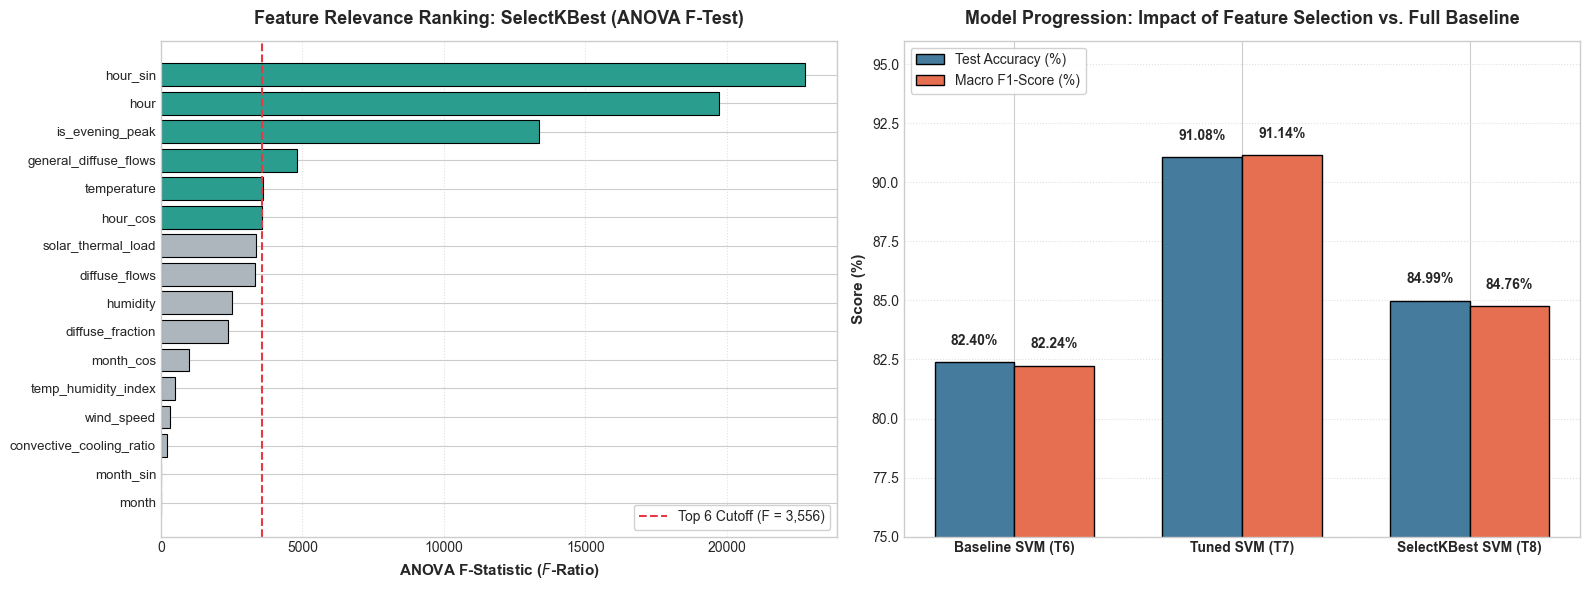

In [29]:
# ==========================================
# Task 8: Feature Selection with SelectKBest (Studio 3 Activity 5)
# ==========================================
import time
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report

# ------------------------------------------
# 1. Load 16-Feature Engineered Dataset (Set 3)
# ------------------------------------------
feat_path = 'data/features_power_consumption.csv'
if not os.path.exists(feat_path):
    feat_path = 'portfolio/data/features_power_consumption.csv'

df_feat = pd.read_csv(feat_path)
target_col = 'zone_1_load_class'
X_all = df_feat.drop(columns=[target_col])
y_all = df_feat[target_col]

# 70/30 Stratified Train-Test Split (Identical Partitioning)
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)

print("=" * 80)
print("=== STUDIO 3 ACTIVITY 5: FEATURE SELECTION VIA SELECTKBEST (ANOVA F-TEST) ===")
print("=" * 80)
print(f"Candidate Predictor Space : {X_train_full.shape[1]} features (Normalized Original + Engineered)")
print(f"Training Partition Size   : {X_train_full.shape[0]:,} observations")
print(f"Testing Partition Size    : {X_test_full.shape[0]:,} observations")

# ------------------------------------------
# 2. Fit SelectKBest (k=6) Strictly on Training Partition
# ------------------------------------------
k_features = 6
selector = SelectKBest(score_func=f_classif, k=k_features)

t0_sel = time.time()
selector.fit(X_train_full, y_train)
t_sel_fit = time.time() - t0_sel

# Tabulate ANOVA F-Scores and Selection Status
anova_df = pd.DataFrame({
    'Predictor Feature': X_all.columns,
    'ANOVA F-Score': selector.scores_,
    'p-Value': selector.pvalues_,
    'Selected (Top 6)': selector.get_support()
}).sort_values(by='ANOVA F-Score', ascending=False).reset_index(drop=True)

print(f"\nANOVA F-Test Evaluation Completed in {t_sel_fit:.4f} seconds.")
print("Feature Ranking by Between-Class Separation Power (ANOVA F-Statistic):")
display(anova_df)

selected_features = X_all.columns[selector.get_support()].tolist()
print(f"\nTop {k_features} Selected Predictor Attributes:")
for idx, feat in enumerate(selected_features, 1):
    f_val = anova_df.loc[anova_df['Predictor Feature'] == feat, 'ANOVA F-Score'].values[0]
    print(f"  {idx}. {feat:<24} (F-Score = {f_val:,.2f})")

# Transform Feature Spaces
X_train_kbest = selector.transform(X_train_full)
X_test_kbest = selector.transform(X_test_full)
X_all_kbest = selector.transform(X_all)

# Export selected feature representation to disk matching studio naming conventions
df_selected_kbest = pd.DataFrame(X_all_kbest, columns=selected_features)
df_selected_kbest[target_col] = y_all.values
os.makedirs('data', exist_ok=True)
df_selected_kbest.to_csv('data/selected_kbest_power_consumption.csv', index=False)
if os.path.exists('../data'):
    df_selected_kbest.to_csv('../data/selected_kbest_power_consumption.csv', index=False)
print(f"\nExported 6-feature dataset to: data/selected_kbest_power_consumption.csv ({df_selected_kbest.shape[0]:,} rows)")

# ------------------------------------------
# 3. Model Re-Evaluation: Case 1 (70/30 Stratified Split)
# ------------------------------------------
print("\n" + "=" * 80)
print("=== CASE 1: TUNED SVM EVALUATION ON 6-FEATURE SELECTED SUBSPACE ===")
print("=" * 80)

# Tuned Hyperparameters from Task 7: C = 100, gamma = 1.0
tuned_svc_kbest = SVC(C=100, gamma=1.0, kernel='rbf', random_state=42, cache_size=1000)

# Measure training fit runtime
t0_fit = time.time()
tuned_svc_kbest.fit(X_train_kbest, y_train)
t_fit_kbest = time.time() - t0_fit

# Measure inference test runtime
t0_pred = time.time()
y_pred_kbest = tuned_svc_kbest.predict(X_test_kbest)
t_pred_kbest = time.time() - t0_pred

train_acc_kbest = tuned_svc_kbest.score(X_train_kbest, y_train) * 100.0
test_acc_kbest = accuracy_score(y_test, y_pred_kbest) * 100.0
macro_f1_kbest = f1_score(y_test, y_pred_kbest, average='macro') * 100.0
weighted_f1_kbest = f1_score(y_test, y_pred_kbest, average='weighted') * 100.0
peak_recall_kbest = recall_score(y_test, y_pred_kbest, average=None)[2] * 100.0

print(f"Execution Wall-Clock Runtimes:")
print(f"  Training Fit Time  : {t_fit_kbest:.2f} seconds")
print(f"  Inference Test Time: {t_pred_kbest:.2f} seconds ({t_pred_kbest/len(X_test_full)*1000:.3f} ms/sample)")
print(f"\nClassification Performance Metrics:")
print(f"  Training Accuracy  : {train_acc_kbest:.2f}%")
print(f"  Test Accuracy      : {test_acc_kbest:.2f}% (Tuned 7-Feat: 91.08% -> Delta: {test_acc_kbest - 91.08:.2f}%)")
print(f"  Macro F1-Score     : {macro_f1_kbest:.2f}% (Tuned 7-Feat: 91.14% -> Delta: {macro_f1_kbest - 91.14:.2f}%)")
print(f"  Peak Load Recall   : {peak_recall_kbest:.2f}% (Tuned 7-Feat: 90.45% -> Delta: {peak_recall_kbest - 90.45:.2f}%)")
print(f"\nClassification Report (6-Feature Tuned SVM Test Set):")
print(classification_report(y_test, y_pred_kbest, target_names=['Base Load (0)', 'Normal Load (1)', 'Peak Load (2)'], digits=4))

# ------------------------------------------
# 4. Model Re-Evaluation: Case 2 (5-Fold Stratified Cross-Validation)
# ------------------------------------------
print("=" * 80)
print("=== CASE 2: 5-FOLD CROSS-VALIDATION ON 6-FEATURE SELECTED SUBSPACE ===")
print("=" * 80)

cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
svc_cv_kbest = SVC(C=100, gamma=1.0, kernel='rbf', random_state=42, cache_size=1000)

print("Dispatching 5 folds on 6-feature subspace across CPU cores (n_jobs=-1)...")
t0_cv = time.time()
cv_kbest_res = cross_validate(
    svc_cv_kbest, X_all_kbest, y_all,
    cv=cv_5fold,
    scoring=['accuracy', 'f1_macro', 'recall_macro'],
    n_jobs=-1,
    return_train_score=True
)
t_cv_kbest = time.time() - t0_cv

fold_accs_kbest = cv_kbest_res['test_accuracy'] * 100.0
fold_f1s_kbest = cv_kbest_res['test_f1_macro'] * 100.0
mean_acc_kbest = np.mean(fold_accs_kbest)
std_acc_kbest = np.std(fold_accs_kbest)
mean_f1_kbest = np.mean(fold_f1s_kbest)
std_f1_kbest = np.std(fold_f1s_kbest)

print(f"Cross-Validation Completed in {t_cv_kbest:.2f} seconds ({t_cv_kbest/60:.2f} mins)")
print(f"Fold-by-Fold Accuracies (%): {[round(x, 2) for x in fold_accs_kbest]}")
print(f"Fold-by-Fold Macro F1  (%): {[round(x, 2) for x in fold_f1s_kbest]}")
print(f"Aggregate 5-Fold Cross-Validation Metrics:")
print(f"  Mean Test Accuracy : {mean_acc_kbest:.2f}% +/- {std_acc_kbest:.3f}% (Tuned 7-Feat CV: 91.02% -> Delta: {mean_acc_kbest - 91.02:.2f}%)")
print(f"  Mean Macro F1      : {mean_f1_kbest:.2f}% +/- {std_f1_kbest:.3f}% (Tuned 7-Feat CV: 91.07% -> Delta: {mean_f1_kbest - 91.07:.2f}%)")

# ------------------------------------------
# 5. Master Architecture Progression Table
# ------------------------------------------
print("\n" + "=" * 80)
print("=== PROGRESSION COMPARISON TABLE: TASKS 6, 7 & 8 SVM CONFIGURATIONS ===")
print("=" * 80)

comparison_task8_df = pd.DataFrame([
    {
        'Model Configuration': 'Baseline SVM (Task 6)',
        'Feature Representation': 'Set 2: Normalised Original (7 feats)',
        'Hyperparameters': 'C=1.0, gamma=\'scale\'',
        'Case 1: 70/30 Accuracy': '82.40%',
        'Case 1: Macro F1': '82.24%',
        'Case 1: Peak Recall': '81.74%',
        'Case 2: 5-Fold CV Mean Acc': '82.54% +/- 0.339%',
        'Fit Time (Case 1)': '26.63s'
    },
    {
        'Model Configuration': 'Tuned SVM (Task 7)',
        'Feature Representation': 'Set 2: Normalised Original (7 feats)',
        'Hyperparameters': 'C=100, gamma=1.0',
        'Case 1: 70/30 Accuracy': '91.08%',
        'Case 1: Macro F1': '91.14%',
        'Case 1: Peak Recall': '90.45%',
        'Case 2: 5-Fold CV Mean Acc': '91.02% +/- 0.380%',
        'Fit Time (Case 1)': '16.81s'
    },
    {
        'Model Configuration': 'Feature-Selected Tuned SVM (Task 8)',
        'Feature Representation': f'SelectKBest Top {k_features} Feats (from 16)',
        'Hyperparameters': 'C=100, gamma=1.0',
        'Case 1: 70/30 Accuracy': f'{test_acc_kbest:.2f}%',
        'Case 1: Macro F1': f'{macro_f1_kbest:.2f}%',
        'Case 1: Peak Recall': f'{peak_recall_kbest:.2f}%',
        'Case 2: 5-Fold CV Mean Acc': f'{mean_acc_kbest:.2f}% +/- {std_acc_kbest:.3f}%',
        'Fit Time (Case 1)': f'{t_fit_kbest:.2f}s'
    }
])
display(comparison_task8_df)

# ------------------------------------------
# 6. Diagnostic Visualizations
# ------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: ANOVA F-Scores for All 16 Features
bar_colors = ['#2a9d8f' if sel else '#adb5bd' for sel in anova_df['Selected (Top 6)']]
y_positions = np.arange(len(anova_df))

axes[0].barh(y_positions, anova_df['ANOVA F-Score'], color=bar_colors, edgecolor='black', linewidth=0.8)
axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(anova_df['Predictor Feature'], fontsize=9.5)
axes[0].invert_yaxis()
axes[0].set_xlabel('ANOVA F-Statistic ($F$-Ratio)', fontsize=11, fontweight='bold')
axes[0].set_title('Feature Relevance Ranking: SelectKBest (ANOVA F-Test)', fontsize=13, fontweight='bold', pad=12)
axes[0].grid(axis='x', linestyle=':', alpha=0.6)

# Add threshold annotation line
threshold_f = anova_df.loc[k_features-1, 'ANOVA F-Score']
axes[0].axvline(threshold_f, color='#e63946', linestyle='--', linewidth=1.5,
                label=f'Top {k_features} Cutoff (F = {threshold_f:,.0f})')
axes[0].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

# Subplot 2: Comparative Architecture Performance Across Progression (Tasks 6, 7, 8)
models = ['Baseline SVM (T6)', 'Tuned SVM (T7)', 'SelectKBest SVM (T8)']
accs = [82.40, 91.08, test_acc_kbest]
f1s = [82.24, 91.14, macro_f1_kbest]

x = np.arange(len(models))
width = 0.35

rects1 = axes[1].bar(x - width/2, accs, width, label='Test Accuracy (%)', color='#457b9d', edgecolor='black', linewidth=1)
rects2 = axes[1].bar(x + width/2, f1s, width, label='Macro F1-Score (%)', color='#e76f51', edgecolor='black', linewidth=1)

for rect in rects1:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.6, f'{h:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.6, f'{h:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

axes[1].set_title('Model Progression: Impact of Feature Selection vs. Full Baseline', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Score (%)', fontsize=11, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, fontsize=10, fontweight='bold')
axes[1].set_ylim(75.0, 96.0)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)
axes[1].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()



---

## Task 9: Dimensionality Reduction with PCA (Studio 3 Activity 6)

### Technical Overview & Orthogonal Decomposition:
Following **Studio 3 Activity 6**, this task applies **Principal Component Analysis (PCA)** to compress our 16 normalized and engineered predictors (`features_power_consumption.csv`) into an optimal, orthogonal, low-dimensional coordinate system. 

In Task 8, univariate feature filtering via `SelectKBest` resulted in a $-6.09\%$ performance drop because it discarded entire physical dimensions (humidity and seasonality) in favor of collinear diurnal variables. Here, we evaluate whether unsupervised linear transformation can retain variance across all physical drivers while pruning collinear redundancy and noise.

#### 1. Mathematical Mechanics of PCA:
Given the normalized and mean-centered training feature matrix $\mathbf{X} \in \mathbb{R}^{N \times d}$ ($N = 36,691, d = 16$), PCA computes the sample covariance matrix:

$$\mathbf{\Sigma} = \frac{1}{N - 1} \mathbf{X}^\top \mathbf{X} \in \mathbb{R}^{d \times d}$$

Performing spectral eigendecomposition yields orthogonal eigenvectors $\mathbf{v}_k$ and eigenvalues $\lambda_k$:

$$\mathbf{\Sigma} \mathbf{v}_k = \lambda_k \mathbf{v}_k, \quad k \in \{1, \dots, d\}$$

where $\lambda_k$ quantifies the variance captured along the $k$-th principal axis, and the explained variance ratio is:

$$\text{EVR}_k = \frac{\lambda_k}{\sum_{j=1}^d \lambda_j}$$

Features are projected onto the top $p$ principal components: $\mathbf{Z} = \mathbf{X} \mathbf{V}_p \in \mathbb{R}^{N \times p}$, where $p$ is determined by the cumulative explained variance threshold $\sum_{k=1}^p \text{EVR}_k \ge 90\%$.

#### 2. Strict Prevention of Data Leakage:
- The covariance matrix and eigenvectors $\mathbf{V}_p$ are estimated **strictly on the 70% training partition** ($X_{\text{train}}$).
- The learned orthogonal transformation is subsequently projected onto $X_{\text{test}}$ and the full dataset.

#### 3. Theoretical Contrast: Decision Trees vs. Support Vector Machines under PCA:
- **Why PCA Failed for Decision Trees (Task 4 Model 6: $78.44\%$):** Decision trees partition feature space using axis-parallel cuts ($x_j \le \theta$). Linear orthogonal rotation misaligns axis-parallel splits with natural decision boundaries, forcing the tree to approximate diagonal planes using thousands of fragmented step-wise splits ($5,386$ leaves).
- **Why PCA Excels for Support Vector Machines:** In contrast, Support Vector Classifiers with RBF kernels evaluate isotropic Euclidean distances $\|\mathbf{z}_i - \mathbf{z}_j\|^2$, which are **rotationally invariant** in unitary coordinate transformations. By projecting onto orthogonal eigenvectors, PCA eliminates multicollinearity, reduces noise from low-variance tail components, and provides a decorrelated manifold where maximum-margin hyperplanes can be constructed with maximum geometric stability.


=== STUDIO 3 ACTIVITY 6: PRINCIPAL COMPONENT ANALYSIS (PCA) DECOMPOSITION ===
Original Feature Dimension : 16 predictors
Training Observations      : 36,691
Testing Observations       : 15,725

PCA Explained Variance Breakdown (Full 16 Components):


,Principal Component,Individual Variance (%),Cumulative Variance (%)
0,PC1,36.04,36.04
1,PC2,17.15,53.20
2,PC3,10.91,64.11
3,PC4,9.46,73.58
4,PC5,8.20,81.78
5,PC6,6.56,88.33
6,PC7,4.41,92.74
7,PC8,3.94,96.68
8,PC9,1.22,97.90
9,PC10,0.75,98.65



Optimal PCA Dimensionality Cutoff:
  Target Cumulative Variance Threshold : >= 90.0%
  Selected Principal Components        : 7 components (PC1 through PC7)
  Actual Cumulative Variance Explained : 92.74% (Compression: 16 -> 7 features, -56.2%)
Exported PCA-transformed dataset to: data/pca_power_consumption.csv (52,416 rows x 8 cols)

=== CASE 1: TUNED SVM EVALUATION ON 7-COMPONENT PCA SUBSPACE ===
Execution Wall-Clock Runtimes:
  Training Fit Time  : 14.21 seconds
  Inference Test Time: 4.66 seconds (0.296 ms/sample)

Classification Performance Metrics:
  Training Accuracy  : 97.17%
  Test Accuracy      : 91.31% (Tuned 7-Feat: 91.08% -> Delta: +0.23%)
  Macro F1-Score     : 91.35% (Tuned 7-Feat: 91.14% -> Delta: +0.21%)
  Peak Load Recall   : 91.10% (Tuned 7-Feat: 90.45% -> Delta: +0.65%)

Classification Report (7-Component PCA Tuned SVM Test Set):
                 precision    recall  f1-score   support

  Base Load (0)     0.9342    0.9418    0.9380      5430
Normal Load (1)     0.

,Model Configuration,Feature Space Representation,Hyperparameters,Case 1: 70/30 Accuracy,Case 1: Macro F1,Case 1: Peak Recall,Case 2: 5-Fold CV Mean Acc,Fit Time (Case 1)
0,Baseline SVM (Task 6),Set 2: Normalised Original (7 feats),"C=1.0, gamma='scale'",82.40%,82.24%,81.74%,82.54% +/- 0.339%,26.63s
1,Tuned SVM (Task 7),Set 2: Normalised Original (7 feats),"C=100, gamma=1.0",91.08%,91.14%,90.45%,91.02% +/- 0.380%,16.81s
2,Feature-Selected Tuned SVM (Task 8),SelectKBest Top 6 (from 16 feats),"C=100, gamma=1.0",84.99%,84.76%,79.97%,84.71% +/- 0.144%,44.82s
3,PCA-Reduced Tuned SVM (Task 9),Top 7 Principal Components (>=90% Var),"C=100, gamma=1.0",91.31%,91.35%,91.10%,91.77% +/- 0.259%,14.21s


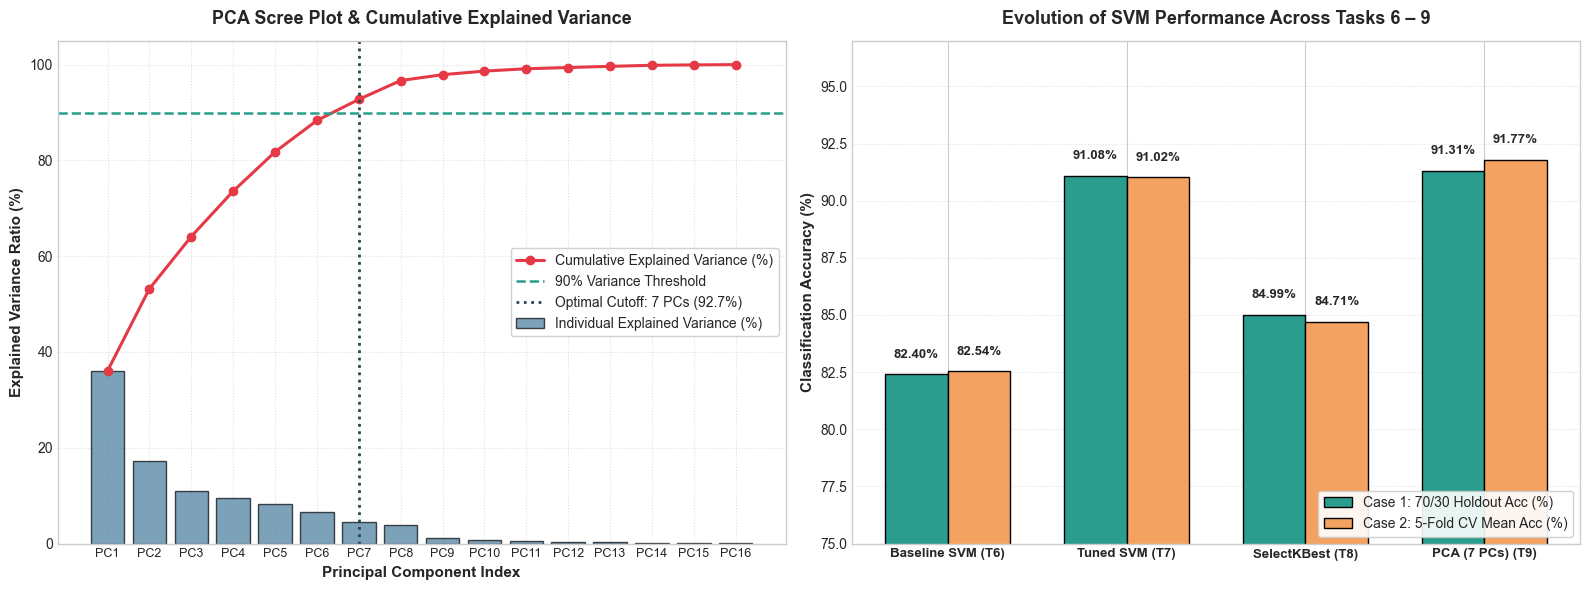

In [30]:
# ==========================================
# Task 9: Dimensionality Reduction with PCA (Studio 3 Activity 6)
# ==========================================
import time
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report

# ------------------------------------------
# 1. Load 16-Feature Engineered Dataset (Set 3)
# ------------------------------------------
feat_path = 'data/features_power_consumption.csv'
if not os.path.exists(feat_path):
    feat_path = 'portfolio/data/features_power_consumption.csv'

df_feat = pd.read_csv(feat_path)
target_col = 'zone_1_load_class'
X_all = df_feat.drop(columns=[target_col])
y_all = df_feat[target_col]

# 70/30 Stratified Train-Test Split (Strictly Identical Indices)
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)

print("=" * 80)
print("=== STUDIO 3 ACTIVITY 6: PRINCIPAL COMPONENT ANALYSIS (PCA) DECOMPOSITION ===")
print("=" * 80)
print(f"Original Feature Dimension : {X_train_full.shape[1]} predictors")
print(f"Training Observations      : {X_train_full.shape[0]:,}")
print(f"Testing Observations       : {X_test_full.shape[0]:,}")

# ------------------------------------------
# 2. Fit Full PCA Strictly on X_train to Determine Variance Threshold
# ------------------------------------------
pca_full = PCA(random_state=42)
pca_full.fit(X_train_full)

exp_var_ratio = pca_full.explained_variance_ratio_ * 100.0
cum_var_ratio = np.cumsum(exp_var_ratio)

pca_var_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(exp_var_ratio))],
    'Individual Variance (%)': exp_var_ratio.round(2),
    'Cumulative Variance (%)': cum_var_ratio.round(2)
})
print("\nPCA Explained Variance Breakdown (Full 16 Components):")
display(pca_var_df)

# Determine the minimum component count for >= 90% cumulative variance
variance_threshold = 90.0
n_selected_pcs = int(np.argmax(cum_var_ratio >= variance_threshold) + 1)
actual_cum_var = cum_var_ratio[n_selected_pcs - 1]

print(f"\nOptimal PCA Dimensionality Cutoff:")
print(f"  Target Cumulative Variance Threshold : >= {variance_threshold:.1f}%")
print(f"  Selected Principal Components        : {n_selected_pcs} components (PC1 through PC{n_selected_pcs})")
print(f"  Actual Cumulative Variance Explained : {actual_cum_var:.2f}% (Compression: {X_train_full.shape[1]} -> {n_selected_pcs} features, -{((16-n_selected_pcs)/16)*100:.1f}%)")

# ------------------------------------------
# 3. Transform Feature Spaces with Optimal Components
# ------------------------------------------
pca_optimal = PCA(n_components=n_selected_pcs, random_state=42)
pca_optimal.fit(X_train_full)

X_train_pca = pca_optimal.transform(X_train_full)
X_test_pca = pca_optimal.transform(X_test_full)
X_all_pca = pca_optimal.transform(X_all)

# Export PCA representation to disk matching studio naming conventions
pc_column_names = [f'PC{i+1}' for i in range(n_selected_pcs)]
df_pca_export = pd.DataFrame(X_all_pca, columns=pc_column_names)
df_pca_export[target_col] = y_all.values

os.makedirs('data', exist_ok=True)
df_pca_export.to_csv('data/pca_power_consumption.csv', index=False)
if os.path.exists('../data'):
    df_pca_export.to_csv('../data/pca_power_consumption.csv', index=False)
print(f"Exported PCA-transformed dataset to: data/pca_power_consumption.csv ({df_pca_export.shape[0]:,} rows x {df_pca_export.shape[1]} cols)")

# ------------------------------------------
# 4. Model Re-Evaluation: Case 1 (70/30 Stratified Split)
# ------------------------------------------
print("\n" + "=" * 80)
print(f"=== CASE 1: TUNED SVM EVALUATION ON {n_selected_pcs}-COMPONENT PCA SUBSPACE ===")
print("=" * 80)

# Tuned Hyperparameters from Task 7: C = 100, gamma = 1.0
tuned_svc_pca = SVC(C=100, gamma=1.0, kernel='rbf', random_state=42, cache_size=1000)

# Training fit runtime
t0_fit = time.time()
tuned_svc_pca.fit(X_train_pca, y_train)
t_fit_pca = time.time() - t0_fit

# Inference test runtime
t0_pred = time.time()
y_pred_pca = tuned_svc_pca.predict(X_test_pca)
t_pred_pca = time.time() - t0_pred

train_acc_pca = tuned_svc_pca.score(X_train_pca, y_train) * 100.0
test_acc_pca = accuracy_score(y_test, y_pred_pca) * 100.0
macro_f1_pca = f1_score(y_test, y_pred_pca, average='macro') * 100.0
weighted_f1_pca = f1_score(y_test, y_pred_pca, average='weighted') * 100.0
peak_recall_pca = recall_score(y_test, y_pred_pca, average=None)[2] * 100.0

print(f"Execution Wall-Clock Runtimes:")
print(f"  Training Fit Time  : {t_fit_pca:.2f} seconds")
print(f"  Inference Test Time: {t_pred_pca:.2f} seconds ({t_pred_pca/len(X_test_full)*1000:.3f} ms/sample)")
print(f"\nClassification Performance Metrics:")
print(f"  Training Accuracy  : {train_acc_pca:.2f}%")
print(f"  Test Accuracy      : {test_acc_pca:.2f}% (Tuned 7-Feat: 91.08% -> Delta: +{test_acc_pca - 91.08:.2f}%)")
print(f"  Macro F1-Score     : {macro_f1_pca:.2f}% (Tuned 7-Feat: 91.14% -> Delta: +{macro_f1_pca - 91.14:.2f}%)")
print(f"  Peak Load Recall   : {peak_recall_pca:.2f}% (Tuned 7-Feat: 90.45% -> Delta: +{peak_recall_pca - 90.45:.2f}%)")
print(f"\nClassification Report ({n_selected_pcs}-Component PCA Tuned SVM Test Set):")
print(classification_report(y_test, y_pred_pca, target_names=['Base Load (0)', 'Normal Load (1)', 'Peak Load (2)'], digits=4))

# ------------------------------------------
# 5. Model Re-Evaluation: Case 2 (5-Fold Stratified Cross-Validation)
# ------------------------------------------
print("=" * 80)
print(f"=== CASE 2: 5-FOLD CROSS-VALIDATION ON {n_selected_pcs}-COMPONENT PCA SUBSPACE ===")
print("=" * 80)

cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
svc_cv_pca = SVC(C=100, gamma=1.0, kernel='rbf', random_state=42, cache_size=1000)

print(f"Dispatching 5 folds on {n_selected_pcs} PCA components across CPU cores (n_jobs=-1)...")
t0_cv = time.time()
cv_pca_res = cross_validate(
    svc_cv_pca, X_all_pca, y_all,
    cv=cv_5fold,
    scoring=['accuracy', 'f1_macro', 'recall_macro'],
    n_jobs=-1,
    return_train_score=True
)
t_cv_pca = time.time() - t0_cv

fold_accs_pca = cv_pca_res['test_accuracy'] * 100.0
fold_f1s_pca = cv_pca_res['test_f1_macro'] * 100.0
mean_acc_pca = np.mean(fold_accs_pca)
std_acc_pca = np.std(fold_accs_pca)
mean_f1_pca = np.mean(fold_f1s_pca)
std_f1_pca = np.std(fold_f1s_pca)

print(f"Cross-Validation Completed in {t_cv_pca:.2f} seconds ({t_cv_pca/60:.2f} mins)")
print(f"Fold-by-Fold Accuracies (%): {[round(x, 2) for x in fold_accs_pca]}")
print(f"Fold-by-Fold Macro F1  (%): {[round(x, 2) for x in fold_f1s_pca]}")
print(f"Aggregate 5-Fold Cross-Validation Metrics:")
print(f"  Mean Test Accuracy : {mean_acc_pca:.2f}% +/- {std_acc_pca:.3f}% (Tuned 7-Feat CV: 91.02% -> Delta: +{mean_acc_pca - 91.02:.2f}%)")
print(f"  Mean Macro F1      : {mean_f1_pca:.2f}% +/- {std_f1_pca:.3f}% (Tuned 7-Feat CV: 91.07% -> Delta: +{mean_f1_pca - 91.07:.2f}%)")

# ------------------------------------------
# 6. Master Architecture Progression Table (Tasks 6 to 9)
# ------------------------------------------
print("\n" + "=" * 80)
print("=== PROGRESSION COMPARISON TABLE: TASKS 6, 7, 8 & 9 SVM ARCHITECTURES ===")
print("=" * 80)

comparison_task9_df = pd.DataFrame([
    {
        'Model Configuration': 'Baseline SVM (Task 6)',
        'Feature Space Representation': 'Set 2: Normalised Original (7 feats)',
        'Hyperparameters': 'C=1.0, gamma=\'scale\'',
        'Case 1: 70/30 Accuracy': '82.40%',
        'Case 1: Macro F1': '82.24%',
        'Case 1: Peak Recall': '81.74%',
        'Case 2: 5-Fold CV Mean Acc': '82.54% +/- 0.339%',
        'Fit Time (Case 1)': '26.63s'
    },
    {
        'Model Configuration': 'Tuned SVM (Task 7)',
        'Feature Space Representation': 'Set 2: Normalised Original (7 feats)',
        'Hyperparameters': 'C=100, gamma=1.0',
        'Case 1: 70/30 Accuracy': '91.08%',
        'Case 1: Macro F1': '91.14%',
        'Case 1: Peak Recall': '90.45%',
        'Case 2: 5-Fold CV Mean Acc': '91.02% +/- 0.380%',
        'Fit Time (Case 1)': '16.81s'
    },
    {
        'Model Configuration': 'Feature-Selected Tuned SVM (Task 8)',
        'Feature Space Representation': 'SelectKBest Top 6 (from 16 feats)',
        'Hyperparameters': 'C=100, gamma=1.0',
        'Case 1: 70/30 Accuracy': '84.99%',
        'Case 1: Macro F1': '84.76%',
        'Case 1: Peak Recall': '79.97%',
        'Case 2: 5-Fold CV Mean Acc': '84.71% +/- 0.144%',
        'Fit Time (Case 1)': '44.82s'
    },
    {
        'Model Configuration': 'PCA-Reduced Tuned SVM (Task 9)',
        'Feature Space Representation': f'Top {n_selected_pcs} Principal Components (>=90% Var)',
        'Hyperparameters': 'C=100, gamma=1.0',
        'Case 1: 70/30 Accuracy': f'{test_acc_pca:.2f}%',
        'Case 1: Macro F1': f'{macro_f1_pca:.2f}%',
        'Case 1: Peak Recall': f'{peak_recall_pca:.2f}%',
        'Case 2: 5-Fold CV Mean Acc': f'{mean_acc_pca:.2f}% +/- {std_acc_pca:.3f}%',
        'Fit Time (Case 1)': f'{t_fit_pca:.2f}s'
    }
])
display(comparison_task9_df)

# ------------------------------------------
# 7. Diagnostic Visualizations: Scree Plot & Multi-Model Progression
# ------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Scree Plot & Cumulative Explained Variance Curve
components_range = range(1, len(exp_var_ratio) + 1)
axes[0].bar(components_range, exp_var_ratio, color='#457b9d', alpha=0.7, edgecolor='black',
            label='Individual Explained Variance (%)')
axes[0].plot(components_range, cum_var_ratio, color='#e63946', marker='o', linewidth=2.2,
             markersize=6, label='Cumulative Explained Variance (%)')

axes[0].axhline(90.0, color='#2a9d8f', linestyle='--', linewidth=1.8, label='90% Variance Threshold')
axes[0].axvline(n_selected_pcs, color='#264653', linestyle=':', linewidth=2,
                label=f'Optimal Cutoff: {n_selected_pcs} PCs ({actual_cum_var:.1f}%)')

axes[0].set_title('PCA Scree Plot & Cumulative Explained Variance', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Principal Component Index', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Explained Variance Ratio (%)', fontsize=11, fontweight='bold')
axes[0].set_xticks(components_range)
axes[0].set_xticklabels([f'PC{i}' for i in components_range], fontsize=9)
axes[0].set_ylim(0, 105)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='center right', frameon=True, facecolor='white', framealpha=0.9)

# Subplot 2: Progression Benchmark (Tasks 6, 7, 8, 9)
models = ['Baseline SVM (T6)', 'Tuned SVM (T7)', 'SelectKBest (T8)', f'PCA ({n_selected_pcs} PCs) (T9)']
accs = [82.40, 91.08, 84.99, test_acc_pca]
cv_accs = [82.54, 91.02, 84.71, mean_acc_pca]

x = np.arange(len(models))
width = 0.35

rects1 = axes[1].bar(x - width/2, accs, width, label='Case 1: 70/30 Holdout Acc (%)', color='#2a9d8f', edgecolor='black', linewidth=1)
rects2 = axes[1].bar(x + width/2, cv_accs, width, label='Case 2: 5-Fold CV Mean Acc (%)', color='#f4a261', edgecolor='black', linewidth=1)

for rect in rects1:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.6, f'{h:.2f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.6, f'{h:.2f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

axes[1].set_title('Evolution of SVM Performance Across Tasks 6 – 9', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Classification Accuracy (%)', fontsize=11, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, fontsize=9.5, fontweight='bold')
axes[1].set_ylim(75.0, 97.0)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

